# Две CI-05 · CSV → два SDK-драйвера → измеренные траектории
Одна 12-суставная цель отправляется координатору, который передаёт обеим рукам **одинаковый абсолютный старт**.
Измерения берутся отдельно из `/left/joint_states` и `/right/joint_states` с исходными timestamp; общего искусственного timestamp нет.
Упреждение читается независимо у каждой руки. CSV содержит только исходные позиции/времена: производные и новые точки не добавляются.

**Безопасность:** параметры баз должны соответствовать стенду. Подвод планируется MoveIt / RRTConnect с проверкой коллизий и границ workspace.
Основной CSV отправляется напрямую, но перед отправкой проверяется в MoveIt по дискретным состояниям.
Это не непрерывная проверка и не защита от движения препятствий во время выполнения. Сначала проверяйте mock и весь путь для реальной двурукой установки.
Разрешение движения одной руки не является проверкой безопасности двух рук. Все переключатели отправки по умолчанию выключены.
Для реального режима дополнительно требуется `CONFIRM_DUAL_PATH_SAFE=True` после проверки обоих путей и геометрии; mock этот флаг не требует.


In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data" / "trajectory_both_TimeGrid_30Hz.csv").is_file()
             and (p / "notebooks").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Запустите Jupyter из корня iimt_manipulation или его notebooks/")
CSV = ROOT / "data" / "trajectory_both_TimeGrid_30Hz.csv"
TIME_SCALE = 1.0       # Масштаб времени: t*s. 1.0 = исходное время.
START_DELAY_S = 3.0    # Старт через 3 s от формирования сообщения: trajectory.header.stamp. Для двух рук нужен положительный запас доставки.
CONFIRM_DUAL_PATH_SAFE = True  # Только после проверки реальной двурукой геометрии и обоих путей.
APPROACH_VELOCITY_SCALE = 0.5
APPROACH_ACCELERATION_SCALE = 0.5
APPROACH_PLANNING_S = 10.0  # Бюджет планирования, не длительность движения.
BASE_JOINTS = ["shoulder_joint", "upper_arm_joint", "forearm_joint",
          "wrist_1_joint", "wrist_2_joint", "wrist_3_joint"]
ARMS = ("left", "right")
JOINTS = [f"{arm}_{joint}" for arm in ARMS for joint in BASE_JOINTS]
CONTROLLER = "/both_arms_controller"
DRIVER_NODES = {arm: f"/{arm}/iimt_ros2_driver" for arm in ARMS}
loaded = approach_prepared = prepared = None

/root/ws/.venv/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/root/ws/.venv/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (
/root/ws/.venv/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1. Загрузить CSV
TIME_SCALE меняет только время: 1.5 → 6 секунд для исходного 4-секундного файла. Позиции неизменны.

In [2]:
loaded = approach_prepared = prepared = None
columns = ["t", *[f"{arm}_q{j}_rad" for arm in ARMS for j in range(1, 7)]]
source = pd.read_csv(CSV, usecols=columns)[columns]
data = source.to_numpy(dtype=float)
if (len(data) < 2 or not np.isfinite(data).all() or np.any(np.diff(data[:, 0]) <= 0)
        or not np.isfinite(TIME_SCALE) or TIME_SCALE <= 0):
    raise ValueError("Нужны конечные позиции, возрастающее время и положительный TIME_SCALE")
t = (data[:, 0] - data[0, 0]) * TIME_SCALE
q = data[:, 1:].copy()
loaded = {"source": str(CSV), "scale": float(TIME_SCALE)}
print(f"{len(t)} исходных точек, {t[-1]:.3f} s, 12 суставов; velocities/accelerations пусты")
display(source.head())

121 исходных точек, 4.000 s, 12 суставов; velocities/accelerations пусты


,t,left_q1_rad,left_q2_rad,left_q3_rad,left_q4_rad,left_q5_rad,left_q6_rad,right_q1_rad,right_q2_rad,right_q3_rad,right_q4_rad,right_q5_rad,right_q6_rad
0,0.000000,0.000000,-1.570796,0.000000,-1.570796,0.000000,0.000000,0.000000,-1.570796,0.000000,-1.570796,0.000000,0.000000
1,0.033333,-0.010731,-1.569326,-0.003866,-1.542065,0.029627,0.000395,-0.034898,-1.570305,-0.003351,-1.543496,0.031203,0.000358
2,0.066667,-0.021462,-1.567855,-0.007733,-1.513334,0.059255,0.000791,-0.069795,-1.569814,-0.006702,-1.516197,0.062406,0.000717
3,0.100000,-0.032193,-1.566385,-0.011599,-1.484603,0.088882,0.001186,-0.104693,-1.569324,-0.010052,-1.488897,0.093609,0.001075
4,0.133333,-0.042924,-1.564914,-0.015466,-1.455872,0.118510,0.001581,-0.139591,-1.568833,-0.013403,-1.461597,0.124812,0.001434


## 2. Подключиться и прочитать параметры
Оба драйвера должны работать в одном ROS clock domain; часы разных компьютеров должны быть синхронизированы. Не запускайте второй клиент поверх первого.

In [3]:
import rclpy
from rclpy.context import Context
from rclpy.duration import Duration as RosDuration
from rclpy.executors import SingleThreadedExecutor
from rclpy.action import ActionClient
from rclpy.qos import qos_profile_sensor_data, QoSProfile, ReliabilityPolicy, DurabilityPolicy
from diagnostic_msgs.msg import DiagnosticArray
from control_msgs.action import FollowJointTrajectory
from moveit_msgs.action import MoveGroup, ExecuteTrajectory
from moveit_msgs.msg import Constraints, JointConstraint, RobotState, PlanningSceneComponents
from moveit_msgs.srv import GetPlanningScene, GetStateValidity
from copy import deepcopy
import json
from rosidl_runtime_py.convert import message_to_ordereddict
from rcl_interfaces.srv import GetParameters
from sensor_msgs.msg import JointState
from trajectory_msgs.msg import JointTrajectoryPoint
from builtin_interfaces.msg import Duration

if globals().get("node") is not None:
    raise RuntimeError("ROS-клиент уже создан: сначала выполните отключение")
ctx = Context()
rclpy.init(context=ctx)
node = rclpy.create_node("iimt_dual_csv_ethernet", context=ctx)
executor = SingleThreadedExecutor(context=ctx)
executor.add_node(node)
client = ActionClient(node, FollowJointTrajectory, f"{CONTROLLER}/follow_joint_trajectory")
planning_client = ActionClient(node, MoveGroup, "/move_action")
execution_client = ActionClient(node, ExecuteTrajectory, "/execute_trajectory")
joint_samples = {arm: [] for arm in ARMS}
pending = None

def outstanding():
    if pending is None or pending.get("rejected", False):
        return False
    future = pending.get("result")
    if future is None or not future.done():
        return True
    try:
        return future.result().status not in (4, 5, 6)  # SUCCEEDED / CANCELED / ABORTED
    except Exception:
        return True  # Завершение future с ошибкой — не подтверждение остановки goal.


def ns(stamp):
    return stamp.sec * 10**9 + stamp.nanosec

def collect(seconds):
    deadline = time.monotonic() + seconds
    while time.monotonic() < deadline:
        executor.spin_once(timeout_sec=min(.02, max(0., deadline-time.monotonic())))

def until(predicate, timeout):
    deadline = time.monotonic() + timeout
    while not predicate() and time.monotonic() < deadline:
        executor.spin_once(timeout_sec=.02)
    if not predicate():
        raise TimeoutError("ROS-запрос не завершился")

def wait(future, timeout):
    until(future.done, timeout)
    return future.result()

def call(kind, name, request=None):
    service = node.create_client(kind, name)
    try:
        if not service.wait_for_service(timeout_sec=5):
            raise RuntimeError(f"Нет {name}: проверьте launch/source/ROS_DOMAIN_ID")
        return wait(service.call_async(request if request is not None else kind.Request()), 5)
    finally:
        node.destroy_client(service)

def on_joints(arm, msg):
    names = [f"{arm}_{j}" for j in BASE_JOINTS]
    if len(msg.name) != len(set(msg.name)) or not set(names).issubset(msg.name):
        return
    if len(msg.position) != len(msg.name):
        return
    values = np.array([msg.position[msg.name.index(j)] for j in names])
    stamp = ns(msg.header.stamp)
    if stamp <= 0 or not np.isfinite(values).all():
        return
    joint_samples[arm].append((stamp, values))
    del joint_samples[arm][:-200]
    if pending is not None:
        pending["record"]["rows"][arm].append([stamp, node.get_clock().now().nanoseconds, *values.tolist()])

subscriptions = [node.create_subscription(JointState, f"/{arm}/joint_states",
    lambda msg, arm=arm: on_joints(arm, msg), qos_profile_sensor_data) for arm in ARMS]

# По UUID храним только последние цели каждого драйвера, включая финализированный старт.
trajectory_timings = {arm: {} for arm in ARMS}

def on_trajectory_timing(arm, message):
    for status in message.status:
        values = {item.key: item.value for item in status.values}
        if status.name != "trajectory_timing" or not values.get("goal_uuid"):
            continue
        try:
            values["receipt_stamp_ns"] = int(values["receipt_stamp_ns"])
            values["nominal_start_stamp_ns"] = int(values["nominal_start_stamp_ns"])
        except (KeyError, ValueError):
            continue
        history = trajectory_timings[arm]
        history[values["goal_uuid"]] = values
        while len(history) > 20:
            del history[next(iter(history))]

timing_qos = QoSProfile(depth=20, reliability=ReliabilityPolicy.RELIABLE,
                        durability=DurabilityPolicy.TRANSIENT_LOCAL)
subscriptions += [node.create_subscription(DiagnosticArray, f"{DRIVER_NODES[arm]}/trajectory_timing",
    lambda msg, arm=arm: on_trajectory_timing(arm, msg), timing_qos) for arm in ARMS]

def one_driver_parameters(arm):
    names = ["enable_motion", "use_mock_hardware", "command_rate", "read_rate",
             "robot_ip", "feedback_transport", "read_timeout", "state_timeout",
             "trajectory_advance_ms", "servo.period", "servo.a", "servo.v", "servo.lookahead_time", "servo.gain",
             "path_tolerance", "goal_tolerance", "goal_time_tolerance",
             *["limits."+key for key in ("min_position", "max_position", "max_velocity", "max_acceleration", "max_step")]]
    values = call(GetParameters, DRIVER_NODES[arm]+"/get_parameters",
                  GetParameters.Request(names=names)).values
    if [v.type for v in values] != [1, 1, 3, 3, 4, 4, 3, 3] + [3]*9 + [8]*5:
        raise RuntimeError("Нужна актуальная сборка iimt_ros2_driver; проверьте параметры обеих нод")
    fields = {1: "bool_value", 3: "double_value", 4: "string_value", 8: "double_array_value"}
    return dict(zip(names, [list(v.double_array_value) if v.type == 8 else getattr(v, fields[v.type])
                            for v in values]))

def driver_parameters():
    result = {arm: one_driver_parameters(arm) for arm in ARMS}
    if len({d["use_mock_hardware"] for d in result.values()}) != 1:
        raise RuntimeError("Смешанный mock/real запуск запрещён")
    if not result["left"]["use_mock_hardware"] and result["left"]["robot_ip"] == result["right"]["robot_ip"]:
        raise RuntimeError("Две реальные руки не должны иметь одинаковый IP")
    return result

def stationary_pose():
    if any(not np.isfinite(d["read_rate"]) or d["read_rate"] <= 0 for d in driver.values()):
        raise RuntimeError("Некорректная частота чтения")
    collect(max(.4, max(4/d["read_rate"] for d in driver.values())))
    now = node.get_clock().now().nanoseconds
    poses = []
    for arm in ARMS:
        d = driver[arm]
        fresh = {stamp: values for stamp, values in joint_samples[arm]
                 if 0 <= (now-stamp)*1e-9 <= max(.3, 3.5/d["read_rate"])}
        if (len(fresh) < 3 or (now-max(fresh))*1e-9 > d["state_timeout"]
                or np.max(np.ptp(list(fresh.values()), axis=0)) > .002):
            raise RuntimeError(f"{arm}: нет свежей неподвижной позы")
        poses.append(fresh[max(fresh)])
    return np.concatenate(poses)

driver = driver_parameters()
for arm, d in driver.items():
    print(arm, "MOCK" if d["use_mock_hardware"] else "REAL "+d["robot_ip"],
          {k: d[k] for k in ("enable_motion", "command_rate", "read_rate", "trajectory_advance_ms")})
display(pd.Series(stationary_pose(), index=JOINTS, name="measured_rad"))

left REAL 192.168.50.95 {'enable_motion': True, 'command_rate': 125.0, 'read_rate': 125.0, 'trajectory_advance_ms': 320.0}
right REAL 192.168.50.163 {'enable_motion': True, 'command_rate': 125.0, 'read_rate': 125.0, 'trajectory_advance_ms': 320.0}


left_shoulder_joint     -0.00046
left_upper_arm_joint    -1.57177
left_forearm_joint      -0.00089
left_wrist_1_joint      -1.57073
left_wrist_2_joint      -0.00046
left_wrist_3_joint      -0.00095
right_shoulder_joint    -0.00086
right_upper_arm_joint   -1.56991
right_forearm_joint     -0.00019
right_wrist_1_joint     -1.57170
right_wrist_2_joint     -0.00031
right_wrist_3_joint     -0.00023
Name: measured_rad, dtype: float64

## 3. Проверки и отправка
Функции не запускают движение. CSV остаётся positions-only; подвод планируется отдельно RRTConnect.
Отмена не заменяет аппаратный E-stop.


In [4]:
def prepare_path(path_t, path_q, path_v, path_a, lead, label):
    if loaded is None or loaded != {"source": str(CSV), "scale": float(TIME_SCALE)}:
        raise RuntimeError("Настройки CSV изменились: повторите чтение файла")
    if (not np.isfinite(path_t).all() or path_t[0] != 0
            or np.any(np.diff(np.rint(path_t*1e9).astype(np.int64)) <= 0)):
        raise ValueError("Нужны положительные длительности и различные ROS-времена")
    if path_v is not None or path_a is not None:
        raise ValueError("CSV передаётся только positions/time")
    if not np.isfinite(path_q).all():
        raise ValueError("Неконечные значения траектории")
    limits = {k: np.concatenate([np.array(driver[arm]["limits."+k]) for arm in ARMS]) for k in
              ("min_position", "max_position", "max_velocity", "max_step")}
    if any(x.shape != (12,) or not np.isfinite(x).all() for x in limits.values()):
        raise ValueError("Некорректные limits.* драйвера")
    h = np.diff(path_t)[:, None]
    delta = np.diff(path_q, axis=0)
    grid, qg = path_t, path_q
    rate = np.repeat([driver[arm]["command_rate"] for arm in ARMS], 6)
    if not np.isfinite(rate).all() or np.any(rate <= 0):
        raise ValueError("Некорректный command_rate")
    limits_ok = bool(np.all(qg >= limits["min_position"]) and np.all(qg <= limits["max_position"])
        and np.all(abs(delta) <= limits["max_velocity"] * h)
        and np.all(abs(delta) <= limits["max_step"] * rate * h))
    display(pd.DataFrame({"joint": JOINTS, "min_q": np.min(path_q, axis=0),
        "max_q": np.max(path_q, axis=0), "limit_min_q": limits["min_position"],
        "limit_max_q": limits["max_position"]}))
    print(label, f"{path_t[-1]:.2f} s; лимиты:", "OK" if limits_ok else "FAIL — отправка заблокирована")
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(grid-lead, qg)
    if label == "CSV": ax.axvspan(0, t[-1], color="gray", alpha=.12)
    ax.set(title=label, xlabel="Время от начала участка, s", ylabel="Задано, rad")
    ax.legend(JOINTS, ncol=6); ax.grid(True); plt.tight_layout()
    return {"driver": driver.copy(), "t": path_t.copy(), "q": path_q.copy(),
        "v": None, "a": None, "csv_t": t.copy(), "csv_q": q.copy(),
        "lead": float(lead), "scale": float(TIME_SCALE), "source": str(CSV),
        "limits_ok": limits_ok, "joints": JOINTS.copy(), "label": label,
        "interpolation": "linear"}

def cancel():
    if pending is not None:
        pending["cancel"] = True
        handle = pending.get("handle")
        if handle is not None and handle.accepted:
            handle.cancel_goal_async()
        collect(3.)
    print("Отмена запрошена; terminal:", not outstanding(), "— это НЕ аппаратный E-stop")

def accepted(future):
    handle = future.result()
    pending["handle"] = handle
    if not handle.accepted:
        pending["rejected"] = True
    else:
        pending["record"]["goal_uuid"] = bytes(handle.goal_id.uuid).hex()
        pending["result"] = handle.get_result_async()
        if pending["cancel"]:
            handle.cancel_goal_async()

def execute_path(plan, record):
    global pending
    if outstanding():
        raise RuntimeError("Предыдущая цель не завершена: сначала cancel() и подтверждение остановки")
    if plan is None:
        raise RuntimeError("Нет успешного предпросмотра: выполните загрузку и подготовку")
    if plan["joints"] != JOINTS or plan["source"] != str(CSV) or plan["scale"] != TIME_SCALE:
        raise RuntimeError("Настройки изменились после предпросмотра: подготовьте путь заново")
    if (not np.array_equal(plan["csv_t"], t) or not np.array_equal(plan["csv_q"], q)
            or not np.array_equal(plan["q"], q) or not np.array_equal(plan["t"], t)):
        raise RuntimeError("CSV изменился после предпросмотра")
    if workspace_scene() != plan.get("scene"):
        raise RuntimeError("Сцена изменилась: повторите предпросмотр CSV")
    current_driver = driver_parameters()
    if not current_driver["left"]["use_mock_hardware"] and not CONFIRM_DUAL_PATH_SAFE:
        raise RuntimeError("Сначала проверьте двурукую геометрию/оба пути и установите CONFIRM_DUAL_PATH_SAFE=True")
    if current_driver != plan["driver"]:
        raise RuntimeError("Параметры драйвера изменились: повторите предпросмотр")
    if not np.isfinite(START_DELAY_S) or START_DELAY_S <= 0:
        raise ValueError("Для двух рук нужен конечный положительный START_DELAY_S")
    if START_DELAY_S < max(d["trajectory_advance_ms"] for d in current_driver.values())*.001 + .5:
        raise ValueError("START_DELAY_S должен превышать упреждение и оставлять запас на доставку цели")
    if not all(d["enable_motion"] for d in current_driver.values()):
        raise RuntimeError("Выполнение целей выключено: enable_motion=false (включая mock)")
    if not plan["limits_ok"]:
        raise RuntimeError("Предпросмотр не прошёл лимиты")
    if np.max(abs(stationary_pose()-plan["q"][0])) > .005:
        raise RuntimeError("Стартовая поза изменилась: повторите предпросмотр")
    if not client.wait_for_server(timeout_sec=5):
        raise RuntimeError("Нет FollowJointTrajectory сервера")
    goal = FollowJointTrajectory.Goal()
    goal.trajectory.joint_names = JOINTS
    for i, ti in enumerate(plan["t"]):
        seconds, nanos = divmod(round(float(ti)*1e9), 10**9)
        point = JointTrajectoryPoint(positions=plan["q"][i].tolist(),
                                    time_from_start=Duration(sec=seconds, nanosec=nanos))
        if plan["v"] is not None: point.velocities = plan["v"][i].tolist()
        if plan["a"] is not None: point.accelerations = plan["a"][i].tolist()
        goal.trajectory.points.append(point)
    # Назначаем абсолютное время ПОСЛЕ подготовки точек, непосредственно перед отправкой.
    request_time = node.get_clock().now()
    if START_DELAY_S > 0:
        goal.trajectory.header.stamp = (request_time + RosDuration(seconds=float(START_DELAY_S))).to_msg()
    record.clear()
    record.update({**plan, "run_id": time.monotonic_ns(), "request_stamp_ns": request_time.nanoseconds, "requested_start_stamp_ns": ns(goal.trajectory.header.stamp), "start_delay_s": float(START_DELAY_S), "status": None, "error_code": None, "error_string": "", "rows": {arm: [] for arm in ARMS}})
    pending = {"cancel": False, "record": record}
    sent_at = time.monotonic()
    try:
        pending["send"] = client.send_goal_async(goal)
        pending["send"].add_done_callback(accepted)
        wait(pending["send"], 5)
        until(lambda: "handle" in pending, 5)  # Ответ и его callback могут исполняться отдельно.
        if pending.get("rejected"):
            raise RuntimeError("Контроллер отверг цель")
        result = wait(pending["result"], float(record["t"][-1])+record["start_delay_s"]+max(d["goal_time_tolerance"] for d in current_driver.values())+5)
        record.update(status=result.status, error_code=result.result.error_code,
                   error_string=result.result.error_string,
                   action_roundtrip_s=time.monotonic()-sent_at)
        collect(.4)
        print({k: record[k] for k in ("status", "error_code", "action_roundtrip_s")})
        if result.status != 4 or result.result.error_code != 0:
            raise RuntimeError(f"Выполнение прервано: {result.result.error_string}")
    except BaseException:
        cancel()
        raise
    finally:
        print({arm: len(record["rows"][arm]) for arm in ARMS}, "измерений; частичная запись доступна при отказе")

def moveit_action(action_client, goal, timeout, record):
    """Единое владение goal: планирование и исполнение используют тот же cancel()."""
    global pending
    if outstanding():
        raise RuntimeError("Предыдущая цель ещё активна/неизвестна")
    if not action_client.wait_for_server(timeout_sec=5):
        raise RuntimeError("Нет MoveIt action server: запустите dual_moveit.launch.py")
    record.update(rows={arm: [] for arm in ARMS})
    pending = {"cancel": False, "record": record}
    try:
        pending["send"] = action_client.send_goal_async(goal)
        pending["send"].add_done_callback(accepted)
        wait(pending["send"], 5)
        until(lambda: "handle" in pending, 5)
        if pending.get("rejected"):
            raise RuntimeError("MoveIt отверг цель")
        result = wait(pending["result"], timeout)
        record.update(status=result.status, error_code=result.result.error_code.val)
        if result.status != 4 or result.result.error_code.val != 1:
            raise RuntimeError(f"MoveIt: status={result.status}, error_code={result.result.error_code.val}")
        return result.result
    except BaseException as error:
        record["execution_error"] = str(error)
        try:
            cancel()
        except Exception as cancel_error:
            record["cancel_error"] = str(cancel_error)
            print(f"Ошибка запроса отмены: {cancel_error}; остановка не подтверждена")
        raise


def measured_state(values):
    state = RobotState()
    state.joint_state.name = JOINTS.copy()
    state.joint_state.position = values.tolist()
    state.joint_state.header.stamp = node.get_clock().now().to_msg()
    state.is_diff = True  # Сохраняем attached tools сцены; все 12 суставов заданы явно.
    return state


def valid_state(values, label):
    response = call(GetStateValidity, "/check_state_validity",
                    GetStateValidity.Request(robot_state=measured_state(values), group_name="both_arms"))
    if not response.valid:
        contacts = [(c.contact_body_1, c.contact_body_2) for c in response.contacts]
        raise RuntimeError(f"{label}: MoveIt считает позу недопустимой; контакты: {contacts}")


def workspace_scene():
    components = PlanningSceneComponents()
    components.components = (PlanningSceneComponents.WORLD_OBJECT_GEOMETRY |
                             PlanningSceneComponents.ALLOWED_COLLISION_MATRIX |
                             PlanningSceneComponents.TRANSFORMS |
                             PlanningSceneComponents.ROBOT_STATE_ATTACHED_OBJECTS |
                             PlanningSceneComponents.OCTOMAP |
                             PlanningSceneComponents.LINK_PADDING_AND_SCALING)
    scene = call(GetPlanningScene, "/get_planning_scene",
                 GetPlanningScene.Request(components=components)).scene
    walls = {"iimt_workspace_x_min", "iimt_workspace_x_max", "iimt_workspace_y_min", "iimt_workspace_y_max"}
    required = walls | {"iimt_workspace_floor"}
    missing = required - {obj.id for obj in scene.world.collision_objects}
    if missing:
        raise RuntimeError(f"В MoveIt отсутствуют границы workspace: {sorted(missing)}")
    for obj in scene.world.collision_objects:
        if obj.id in walls and (obj.header.frame_id != "world" or len(obj.primitives) != 1
                or obj.primitives[0].type != 1 or len(obj.primitives[0].dimensions) != 3
                or not all(np.isfinite(obj.primitives[0].dimensions))
                or min(obj.primitives[0].dimensions) <= 0):
            raise RuntimeError(f"Некорректная граница workspace: {obj.id}")
    floor = next(obj for obj in scene.world.collision_objects if obj.id == "iimt_workspace_floor")
    if (floor.header.frame_id != "world" or len(floor.planes) != 1 or len(floor.plane_poses) != 1
            or floor.primitives or floor.meshes
            or not np.isfinite(floor.planes[0].coef).all()
            or not np.allclose(floor.planes[0].coef[:3], [0., 0., 1.])):
        raise RuntimeError("Некорректная плоскость пола в MoveIt")
    floor_pose = floor.plane_poses[0]
    if not np.allclose([floor_pose.position.x, floor_pose.position.y, floor_pose.position.z,
                        floor_pose.orientation.x, floor_pose.orientation.y,
                        floor_pose.orientation.z, floor_pose.orientation.w], [0., 0., 0., 0., 0., 0., 1.]):
        raise RuntimeError("Некорректная поза пола: высота задаётся коэффициентом плоскости")
    # Не включаем меняющийся timestamp текущего состояния в отпечаток сцены.
    # CDR содержит padding: одинаковые сообщения не обязаны иметь одинаковые bytes.
    # JSON-представление сохраняет геометрию, ACM, инструменты и occupancy map.
    geometry = {"world": message_to_ordereddict(scene.world),
                "acm": message_to_ordereddict(scene.allowed_collision_matrix),
                "transforms": [message_to_ordereddict(tf) for tf in scene.fixed_frame_transforms],
                "attached": [message_to_ordereddict(obj) for obj in scene.robot_state.attached_collision_objects],
                "padding": [message_to_ordereddict(item) for item in scene.link_padding],
                "scaling": [message_to_ordereddict(item) for item in scene.link_scale]}
    return json.dumps(geometry, sort_keys=True, separators=(",", ":"))


def approach_settings():
    return (float(APPROACH_VELOCITY_SCALE), float(APPROACH_ACCELERATION_SCALE),
            float(APPROACH_PLANNING_S))


def validate_csv_collisions():
    """Проверочные состояния НЕ добавляются в отправляемые точки CSV."""
    snapshot = workspace_scene()
    rate = max(d["command_rate"] for d in driver.values())
    grid = np.unique(np.r_[t, np.linspace(0, t[-1], int(np.ceil(t[-1]*rate))+1)])
    service = node.create_client(GetStateValidity, "/check_state_validity")
    try:
        if not service.wait_for_service(timeout_sec=5):
            raise RuntimeError("Нет /check_state_validity")
        for ti in grid:
            values = np.array([np.interp(ti, t, q[:, j]) for j in range(12)])
            request = GetStateValidity.Request(robot_state=measured_state(values), group_name="both_arms")
            response = wait(service.call_async(request), 5)
            if not response.valid:
                contacts = [(c.contact_body_1, c.contact_body_2) for c in response.contacts]
                raise RuntimeError(f"CSV недопустим при t={ti:.6f} s; контакты: {contacts}")
    finally:
        node.destroy_client(service)
    if workspace_scene() != snapshot:
        raise RuntimeError("Сцена изменилась во время проверки CSV; повторите предпросмотр")
    print(f"CSV: {len(grid)} проверочных состояний без коллизий; отправляемые точки не менялись")
    return snapshot



def nominal_execution_start(record):
    """Только опубликованный старт конкретных дочерних целей, без подгонки времени."""
    matched = {}
    for arm in ARMS:
        candidates = [entry for entry in trajectory_timings[arm].values()
            if record["request_stamp_ns"] <= entry["receipt_stamp_ns"] <= record["finish_stamp_ns"]]
        if len(candidates) != 1:
            raise RuntimeError(f"{arm}: ожидалась одна дочерняя цель в интервале исполнения, найдено {len(candidates)}")
        entry = candidates[0]
        if entry.get("nominal_start_final") != "true" or entry["nominal_start_stamp_ns"] <= 0:
            raise RuntimeError(f"{arm}: нет финального nominal_start_stamp_ns")
        matched[arm] = entry.copy()
    starts = {entry["nominal_start_stamp_ns"] for entry in matched.values()}
    if len(starts) != 1:
        raise RuntimeError("Дочерние цели имеют разные nominal_start_stamp_ns; общий график не строится")
    record["timing"] = matched
    record["nominal_start_stamp_ns"] = starts.pop()
    return record["nominal_start_stamp_ns"]


def planned_positions(trajectory, elapsed, stationary_start):
    """Позиции как trajectory.hpp: линейная / кубическая / квинтическая интерполяция."""
    jt = trajectory.joint_trajectory
    if len(jt.joint_names) != 12 or set(jt.joint_names) != set(JOINTS) or not jt.points:
        raise ValueError("Для графика нужен полный план 12 суставов")
    order = [jt.joint_names.index(joint) for joint in JOINTS]
    times = np.array([ns(point.time_from_start)*1e-9 for point in jt.points])
    if times[0] < 0 or np.any(np.diff(times) <= 0):
        raise ValueError("Некорректные времена плана")
    sizes = {(len(p.positions), len(p.velocities), len(p.accelerations)) for p in jt.points}
    if len(sizes) != 1 or next(iter(sizes)) not in {(12, 0, 0), (12, 12, 0), (12, 12, 12)}:
        raise ValueError("Несогласованные производные плана")
    _, nv, na = next(iter(sizes))
    positions = np.array([[p.positions[i] for i in order] for p in jt.points])
    velocities = np.array([[p.velocities[i] for i in order] for p in jt.points]) if nv else np.zeros_like(positions)
    accelerations = np.array([[p.accelerations[i] for i in order] for p in jt.points]) if na else np.zeros_like(positions)
    if not np.isfinite(np.r_[positions, velocities, accelerations]).all():
        raise ValueError("Неконечные значения плана")
    if times[0] > 0:
        # Драйвер тоже добавляет t=0 с измеренной позой и нулевыми производными.
        # Здесь используется сохранённая неподвижная поза перед отправкой; это не новый узел отправляемого плана.
        times = np.r_[0., times]
        positions = np.vstack([stationary_start, positions])
        velocities = np.vstack([np.zeros(12), velocities])
        accelerations = np.vstack([np.zeros(12), accelerations])
    elapsed = np.asarray(elapsed, dtype=float)
    if len(times) == 1:
        return np.tile(positions[0], (len(elapsed), 1))
    index = np.clip(np.searchsorted(times, elapsed, side="right")-1, 0, len(times)-2)
    h = (times[index+1]-times[index])[:, None]
    u = np.clip((elapsed-times[index])[:, None]/h, 0., 1.)
    delta = positions[index+1]-positions[index]
    c0 = positions[index]
    c1 = h*velocities[index] if nv else delta
    c2 = np.zeros_like(delta); c3 = c2.copy(); c4 = c2.copy(); c5 = c2.copy()
    if nv and not na:
        c2 = 3*delta-2*c1-h*velocities[index+1]
        c3 = -2*delta+c1+h*velocities[index+1]
    elif na:
        c2 = .5*accelerations[index]*h*h
        d = delta-c1-c2
        e = h*velocities[index+1]-c1-2*c2
        f = h*h*accelerations[index+1]-2*c2
        c3, c4, c5 = 10*d-4*e+.5*f, -15*d+7*e-f, 6*d-3*e+.5*f
    return ((((c5*u+c4)*u+c3)*u+c2)*u+c1)*u+c0


def plot_random_execution(record):
    """При отказе показываем имеющиеся данные; без точного старта не вычисляем ошибку."""
    from matplotlib.ticker import MaxNLocator

    warnings = []
    try:
        start_ns = nominal_execution_start(record)
    except RuntimeError as error:
        start_ns = None
        warnings.append(f"Нет подтверждённого общего старта: {error}. Показаны только измерения.")
    trajectory = record["trajectory"]
    duration = ns(trajectory.joint_trajectory.points[-1].time_from_start)*1e-9
    frames, metrics = {}, []
    for arm_index, arm in enumerate(ARMS):
        raw = pd.DataFrame(record.get("rows", {}).get(arm, []),
            columns=["stamp_ns", "receive_ns", *[f"q{j}" for j in range(1, 7)]])
        stamps = raw.stamp_ns.to_numpy(dtype=np.int64)
        monotonic = not np.any(np.diff(stamps) < 0)
        if raw.empty:
            warnings.append(f"{arm}: измерения не получены")
        elif not monotonic:
            warnings.append(f"{arm}: timestamp идут назад; ошибка не рассчитывается")
        elapsed = (stamps-start_ns)*1e-9 if start_ns is not None else np.full(len(raw), np.nan)
        inside = (elapsed >= 0) & (elapsed <= duration) & monotonic
        # Повторный timestamp не должен увеличивать вес образца в метриках.
        inside &= ~raw.stamp_ns.duplicated().to_numpy()
        desired = (planned_positions(trajectory, elapsed, record["start"])[:, arm_index*6:(arm_index+1)*6]
                   if start_ns is not None else np.full((len(raw), 6), np.nan))
        measured = raw[[f"q{j}" for j in range(1, 7)]].to_numpy(dtype=float)
        errors = measured-desired
        raw["elapsed_s"] = elapsed
        if start_ns is not None and not inside.any():
            warnings.append(f"{arm}: нет пригодных измерений внутри номинального интервала; метрики NaN")
        for j in range(6):
            raw[f"desired_q{j+1}"] = desired[:, j]
            raw[f"error_q{j+1}"] = np.where(inside, errors[:, j], np.nan)
            metrics.append({"arm": arm, "joint": JOINTS[arm_index*6+j], "samples": int(inside.sum()),
                "rmse_rad": float(np.sqrt(np.mean(errors[inside, j]**2))) if inside.any() else np.nan,
                "max_abs_rad": float(np.max(abs(errors[inside, j]))) if inside.any() else np.nan})
        frames[arm] = raw
    if start_ns is not None:
        grid = np.unique(np.r_[np.linspace(0., duration, max(2, int(np.ceil(duration*125))+1)),
            [ns(p.time_from_start)*1e-9 for p in trajectory.joint_trajectory.points]])
        desired_grid = planned_positions(trajectory, grid, record["start"])
    figure, axes = plt.subplots(6, 4, figsize=(19, 18), sharex=True)
    for arm_index, arm in enumerate(ARMS):
        raw = frames[arm]
        for j in range(6):
            axis, error_axis = axes[j, arm_index*2:arm_index*2+2]
            if start_ns is not None:
                axis.plot(start_ns*1e-9+grid, desired_grid[:, arm_index*6+j], label="Полный план RRTConnect")
            else:
                axis.text(.02, .95, "Старт плана неизвестен", transform=axis.transAxes, va="top")
            if not raw.empty:
                axis.plot(raw.stamp_ns.to_numpy(dtype=np.int64)*1e-9, raw[f"q{j+1}"], label="Измерено")
            else:
                axis.text(.5, .5, "Нет измерений", transform=axis.transAxes, ha="center")
            if raw[f"error_q{j+1}"].notna().any():
                error_axis.plot(raw.stamp_ns.to_numpy(dtype=np.int64)*1e-9, raw[f"error_q{j+1}"])
            else:
                error_axis.text(.5, .5, "Недостаточно данных для ошибки", transform=error_axis.transAxes, ha="center", fontsize=8)
            axis.set_ylabel(f"{arm} J{j+1}, rad"); error_axis.set_ylabel("Ошибка, rad")
            for ax in (axis, error_axis):
                ax.grid(True); ax.ticklabel_format(axis="x", style="plain", useOffset=False)
    for ax in axes[-1]:
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.tick_params(axis="x", labelrotation=25)
        ax.set_xlabel("Unix timestamp UTC, s")
    for ax in (axes[0, 0], axes[0, 2]):
        if ax.lines: ax.legend()
    title = f"{record.get('label', 'Случайное движение')}: nominal_start={start_ns} ns; status={record.get('status')}"
    if record.get("execution_error"):
        title += f"\nПрервано: {record['execution_error']}"
    figure.suptitle(title)
    figure.tight_layout()
    record.update(frames=frames, metrics=pd.DataFrame(metrics), figure=figure, plot_warnings=warnings)
    for warning in warnings: print(warning)
    display(record["metrics"])
    plt.show()


def finish_execution_plot(record):
    """Вызывается из finally: сбой сбора/графика не скрывает исходный отказ движения."""
    record["finish_stamp_ns"] = node.get_clock().now().nanoseconds
    try:
        collect(.4)
    except Exception as error:
        record["collect_error"] = str(error)
        print(f"Дополнительный сбор измерений прерван: {error}")
    try:
        plot_random_execution(record)
    except Exception as error:
        record["plot_error"] = str(error)
        print(f"Не удалось построить график; исходные rows сохранены: {error}")


## 4. Отдельный подвод — план RRTConnect (без движения)
MoveIt планирует обе руки вместе от свежей измеренной позы к первой точке CSV.
Проверяются старт/цель и наличие четырёх границ workspace. Недопустимая поза — ошибка, без обхода проверок.
Скорость/ускорение ограничены масштабами 0.1; длительность определяет MoveIt, а не фиксированный таймер.


План готов: 3 точек, 0.111 s. Движение НЕ запускалось.


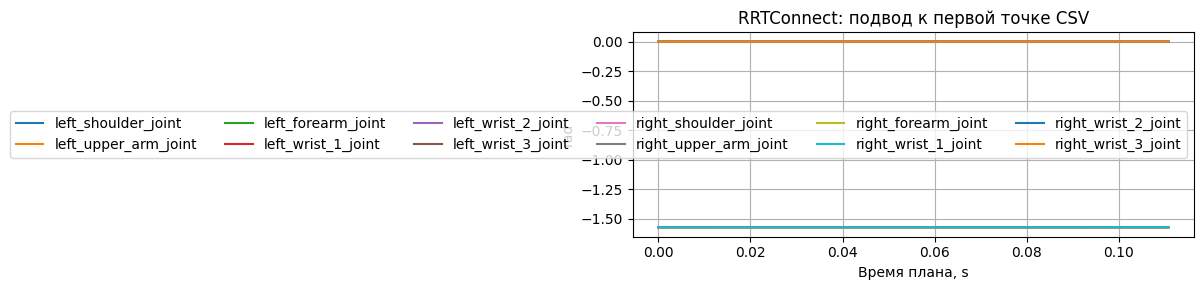

In [5]:
approach_prepared = None
if outstanding():
    raise RuntimeError("Сначала дождитесь завершения предыдущей цели")
if loaded != {"source": str(CSV), "scale": float(TIME_SCALE)}:
    raise RuntimeError("Повторите загрузку CSV")
velocity_scale, acceleration_scale, planning_s = approach_settings()
if (not all(np.isfinite(approach_settings())) or not 0 < velocity_scale <= 1
        or not 0 < acceleration_scale <= 1 or planning_s <= 0):
    raise ValueError("Масштабы должны быть в (0, 1], время планирования > 0")
driver = driver_parameters()
start_q = stationary_pose()
scene_snapshot = workspace_scene()
valid_state(start_q, "Старт подвода")
valid_state(q[0], "Первая точка CSV")
goal = MoveGroup.Goal()
goal.request.group_name = "both_arms"
goal.request.pipeline_id = "move_group"
goal.request.planner_id = "RRTConnect"
goal.request.allowed_planning_time = planning_s
goal.request.num_planning_attempts = 1
goal.request.max_velocity_scaling_factor = velocity_scale
goal.request.max_acceleration_scaling_factor = acceleration_scale
goal.request.start_state = measured_state(start_q)
constraints = Constraints()
constraints.joint_constraints = [JointConstraint(joint_name=name, position=float(value),
    tolerance_above=0.001, tolerance_below=0.001, weight=1.0) for name, value in zip(JOINTS, q[0])]
goal.request.goal_constraints = [constraints]
goal.planning_options.plan_only = True
goal.planning_options.replan = False
planning_record = {}
response = moveit_action(planning_client, goal, planning_s+10, planning_record)
trajectory = response.planned_trajectory
jt = trajectory.joint_trajectory
if len(jt.joint_names) != 12 or set(jt.joint_names) != set(JOINTS) or len(jt.points) < 2:
    raise RuntimeError("MoveIt не вернул полную траекторию 12 суставов")
order = [jt.joint_names.index(name) for name in JOINTS]
planned_q = np.array([[point.positions[i] for i in order] for point in jt.points])
planned_t = np.array([ns(point.time_from_start)*1e-9 for point in jt.points])
if (not np.isfinite(planned_q).all() or np.any(np.diff(planned_t) <= 0)
        or np.max(abs(planned_q[0]-start_q)) > .005
        or np.max(abs(planned_q[-1]-q[0])) > .005):
    raise RuntimeError("План не соответствует измеренному старту/цели CSV")
approach_prepared = {"trajectory": trajectory, "trajectory_snapshot": deepcopy(trajectory),
    "driver": driver.copy(), "source": str(CSV), "scale": float(TIME_SCALE),
    "csv_t": t.copy(), "csv_q": q.copy(), "start_q": start_q.copy(),
    "scene": scene_snapshot, "settings": approach_settings(), "duration": float(planned_t[-1])}
fig_approach, ax = plt.subplots(figsize=(10, 3))
ax.plot(planned_t, planned_q)
ax.set(title="RRTConnect: подвод к первой точке CSV", xlabel="Время плана, s", ylabel="rad")
ax.legend(JOINTS, ncol=6); ax.grid(True); plt.tight_layout()
print(f"План готов: {len(jt.points)} точек, {planned_t[-1]:.3f} s. Движение НЕ запускалось.")


### Выполнить только подвод
Установите RUN_APPROACH=True после проверки стенда. CSV автоматически не запускается.

,arm,joint,samples,rmse_rad,max_abs_rad
0,left,left_shoulder_joint,14,0.000385,0.000599
1,left,left_upper_arm_joint,14,0.000122,0.000188
2,left,left_forearm_joint,14,0.000016,0.000027
3,left,left_wrist_1_joint,14,0.000009,0.000012
4,left,left_wrist_2_joint,14,0.000191,0.000287
5,left,left_wrist_3_joint,14,0.000079,0.000127
6,right,right_shoulder_joint,14,0.000502,0.000814
7,right,right_upper_arm_joint,14,0.000293,0.000478
8,right,right_forearm_joint,14,0.000151,0.000237
9,right,right_wrist_1_joint,14,0.000530,0.000874


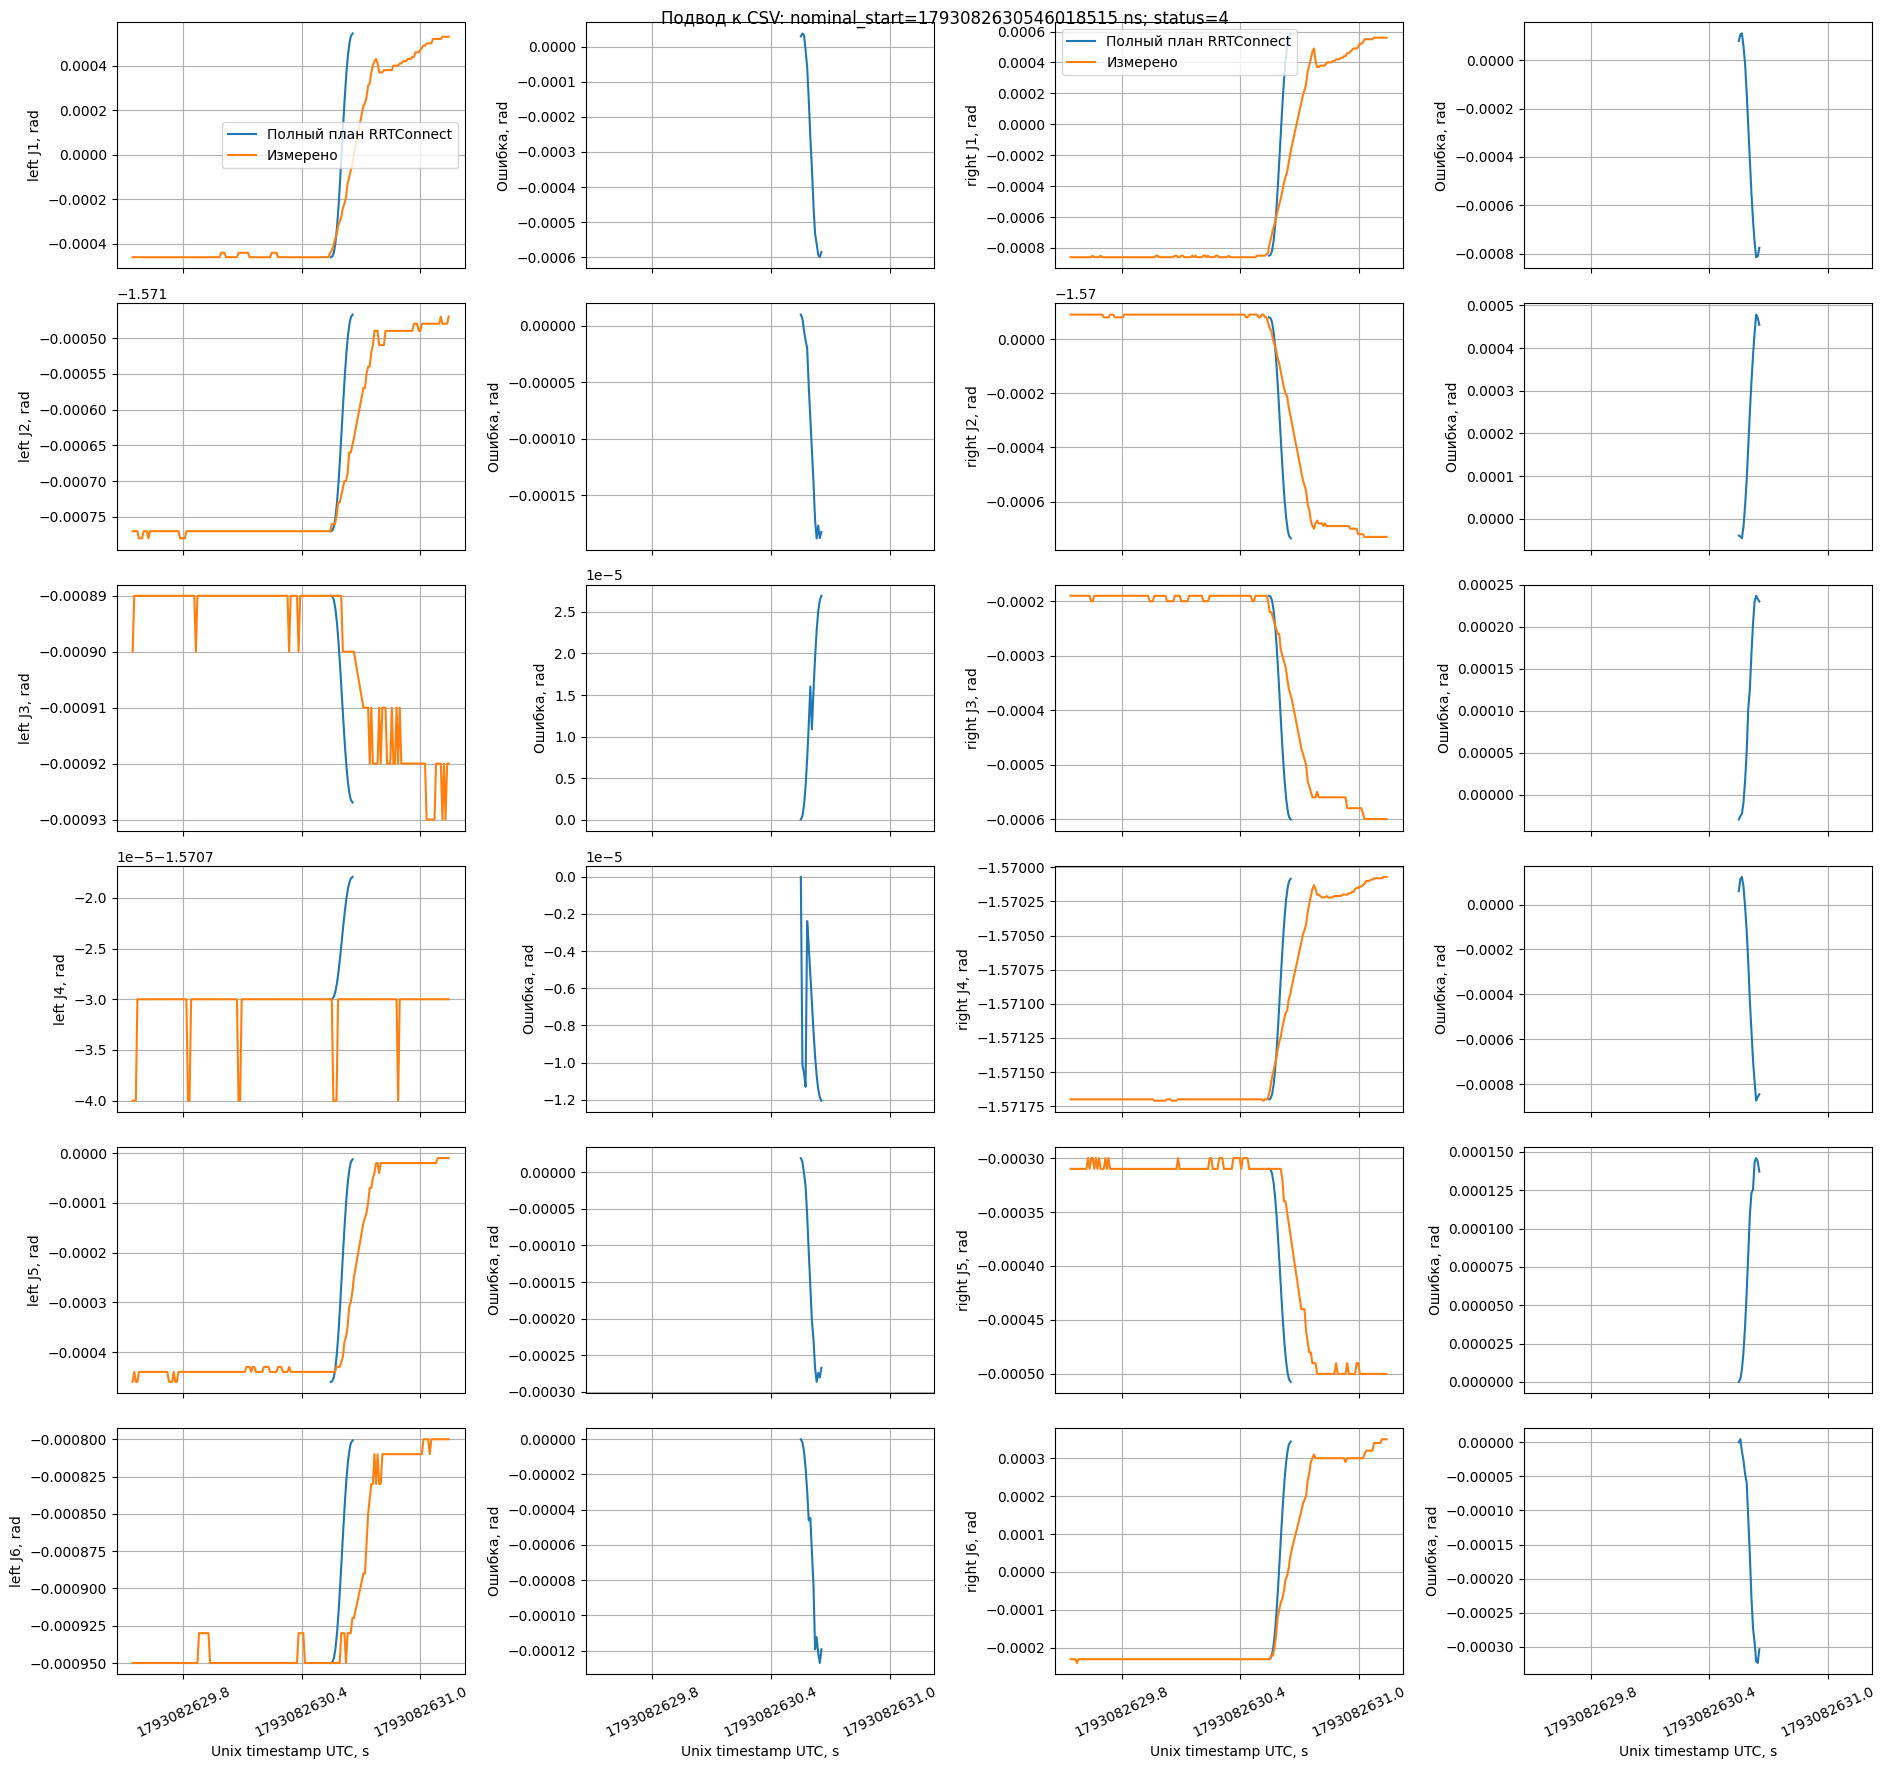

Подвод MoveIt завершён; CSV НЕ запускался.


In [6]:
RUN_APPROACH = True  # Разрешите одну попытку после проверки плана и модели.
if not RUN_APPROACH:
    print("RUN_APPROACH=False: подвод не отправлен")
else:
    RUN_APPROACH = False
    if outstanding():
        raise RuntimeError("Предыдущая цель ещё активна/неизвестна: сначала cancel()")
    plan = approach_prepared
    if plan is None:
        raise RuntimeError("Сначала получите успешный план RRTConnect")
    if (plan["source"] != str(CSV) or plan["scale"] != TIME_SCALE
            or plan["settings"] != approach_settings()
            or not np.array_equal(plan["csv_t"], t) or not np.array_equal(plan["csv_q"], q)
            or plan["trajectory"] != plan["trajectory_snapshot"]):
        raise RuntimeError("CSV/настройки/план изменились: повторите планирование")
    driver = driver_parameters()
    if driver != plan["driver"] or not all(d["enable_motion"] for d in driver.values()):
        raise RuntimeError("Параметры изменились или enable_motion=false: повторите подготовку")
    if not driver["left"]["use_mock_hardware"] and not CONFIRM_DUAL_PATH_SAFE:
        raise RuntimeError("Сначала подтвердите геометрию и безопасность стенда: CONFIRM_DUAL_PATH_SAFE=True")
    if workspace_scene() != plan["scene"]:
        raise RuntimeError("Сцена изменилась: повторите планирование")
    current_q = stationary_pose()
    if np.max(abs(current_q-plan["start_q"])) > .005:
        raise RuntimeError("Стартовая поза изменилась: повторите планирование")
    valid_state(current_q, "Текущий старт")
    valid_state(q[0], "Цель CSV")
    prepared = None
    approach_run = {"trajectory": deepcopy(plan["trajectory"]), "start": current_q.copy(),
                    "driver": deepcopy(driver), "label": "Подвод к CSV",
                    "request_stamp_ns": node.get_clock().now().nanoseconds}
    execute_goal = ExecuteTrajectory.Goal(trajectory=plan["trajectory"])
    try:
        moveit_action(execution_client, execute_goal, plan["duration"]+30, approach_run)
    finally:
        finish_execution_plot(approach_run)
    reached = stationary_pose()
    if np.max(abs(reached-q[0])) > .005:
        raise RuntimeError("Начальная поза не достигнута/не удерживается")
    print("Подвод MoveIt завершён; CSV НЕ запускался.")


## 5. Предпросмотр исходного CSV
Обе руки должны уже стоять в первых точках файла.
Линейный путь CSV проверяется в MoveIt на исходных узлах и с шагом не больше периода быстрейшего драйвера.
Это только проверочные состояния — отправляемые узлы CSV не меняются. Дискретная проверка не гарантирует отсутствие коллизий между образцами.


,joint,min_q,max_q,limit_min_q,limit_max_q
0,left_shoulder_joint,-3.201323,0.000000,-6.2832,6.2832
1,left_upper_arm_joint,-1.589143,-1.446963,-2.6167,2.6167
2,left_forearm_joint,-0.671894,0.000000,-2.8783,2.8783
3,left_wrist_1_joint,-1.570796,1.944057,-3.0528,3.0528
4,left_wrist_2_joint,-0.740006,0.608159,-3.0528,3.0528
5,left_wrist_3_joint,-0.066722,0.024168,-6.2832,6.2832
6,right_shoulder_joint,-2.600024,0.000000,-6.2832,6.2832
7,right_upper_arm_joint,-1.580348,-1.498745,-2.6167,2.6167
8,right_forearm_joint,-0.040857,0.587570,-2.8783,2.8783
9,right_wrist_1_joint,-1.570796,-1.154382,-3.0528,3.0528


CSV 4.00 s; лимиты: OK
CSV: 620 проверочных состояний без коллизий; отправляемые точки не менялись
Только 121 точек CSV, 4.000 s; скорости/ускорения из файла не используются


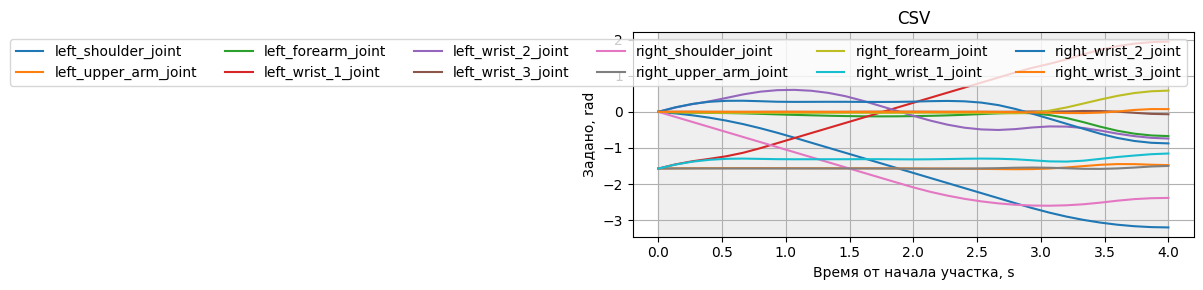

In [7]:
prepared = None
if outstanding():
    raise RuntimeError("Сначала дождитесь завершения подвода")
if loaded != {"source": str(CSV), "scale": float(TIME_SCALE)}:
    raise RuntimeError("Повторите загрузку CSV")
driver = driver_parameters()
if np.max(abs(stationary_pose()-q[0])) > .005:
    raise RuntimeError("Робот не в начале CSV: выполните отдельную ячейку подвода")
candidate = prepare_path(t.copy(), q.copy(), None, None, 0., "CSV")
if not candidate["limits_ok"]:
    raise RuntimeError("CSV нарушает лимиты")
candidate["scene"] = validate_csv_collisions()
prepared = candidate
print(f"Только {len(t)} точек CSV, {t[-1]:.3f} s; скорости/ускорения из файла не используются")

### Выполнить CSV
Один future header.stamp задаётся после формирования всех точек. START_DELAY_S отсчитывается **от отправителя**, не от приёма сообщения сервером. Общая номинальная шкала не гарантирует физическую синхронность роботов; проверяйте графики и индивидуальные упреждения.

In [8]:
RUN_MOTION = True  # Только позиции/время CSV; отдельный подвод не запускается.
if not RUN_MOTION:
    print("RUN_MOTION=False: CSV не отправлен")
else:
    RUN_MOTION = False
    if outstanding():
        raise RuntimeError("Предыдущая цель ещё активна/неизвестна: сначала cancel()")
    analysis_run_id = None
    run = {}
    execute_path(prepared, run)

{'status': 4, 'error_code': 0, 'action_roundtrip_s': 7.077634184999624}
{'left': 930, 'right': 930} измерений; частичная запись доступна при отказе


## 6. Глобальное время, траектории и ошибки
Каждая рука сравнивается с CSV на её собственном измерительном timestamp. Нет сдвига кривых для улучшения совпадения. Ошибка = измерено − задано. У dashboard timestamp означает завершение чтения, а не известное время энкодера.

,arm,joint,samples,rmse_rad,max_abs_rad
0,left,left_shoulder_joint,500,0.009638,0.021401
1,left,left_upper_arm_joint,500,0.002268,0.008696
2,left,left_forearm_joint,500,0.005627,0.018092
3,left,left_wrist_1_joint,500,0.006362,0.019418
4,left,left_wrist_2_joint,500,0.010179,0.024622
5,left,left_wrist_3_joint,500,0.002427,0.012324
6,right,right_shoulder_joint,500,0.006823,0.013776
7,right,right_upper_arm_joint,500,0.002565,0.010287
8,right,right_forearm_joint,500,0.006907,0.022205
9,right,right_wrist_1_joint,500,0.010037,0.021015


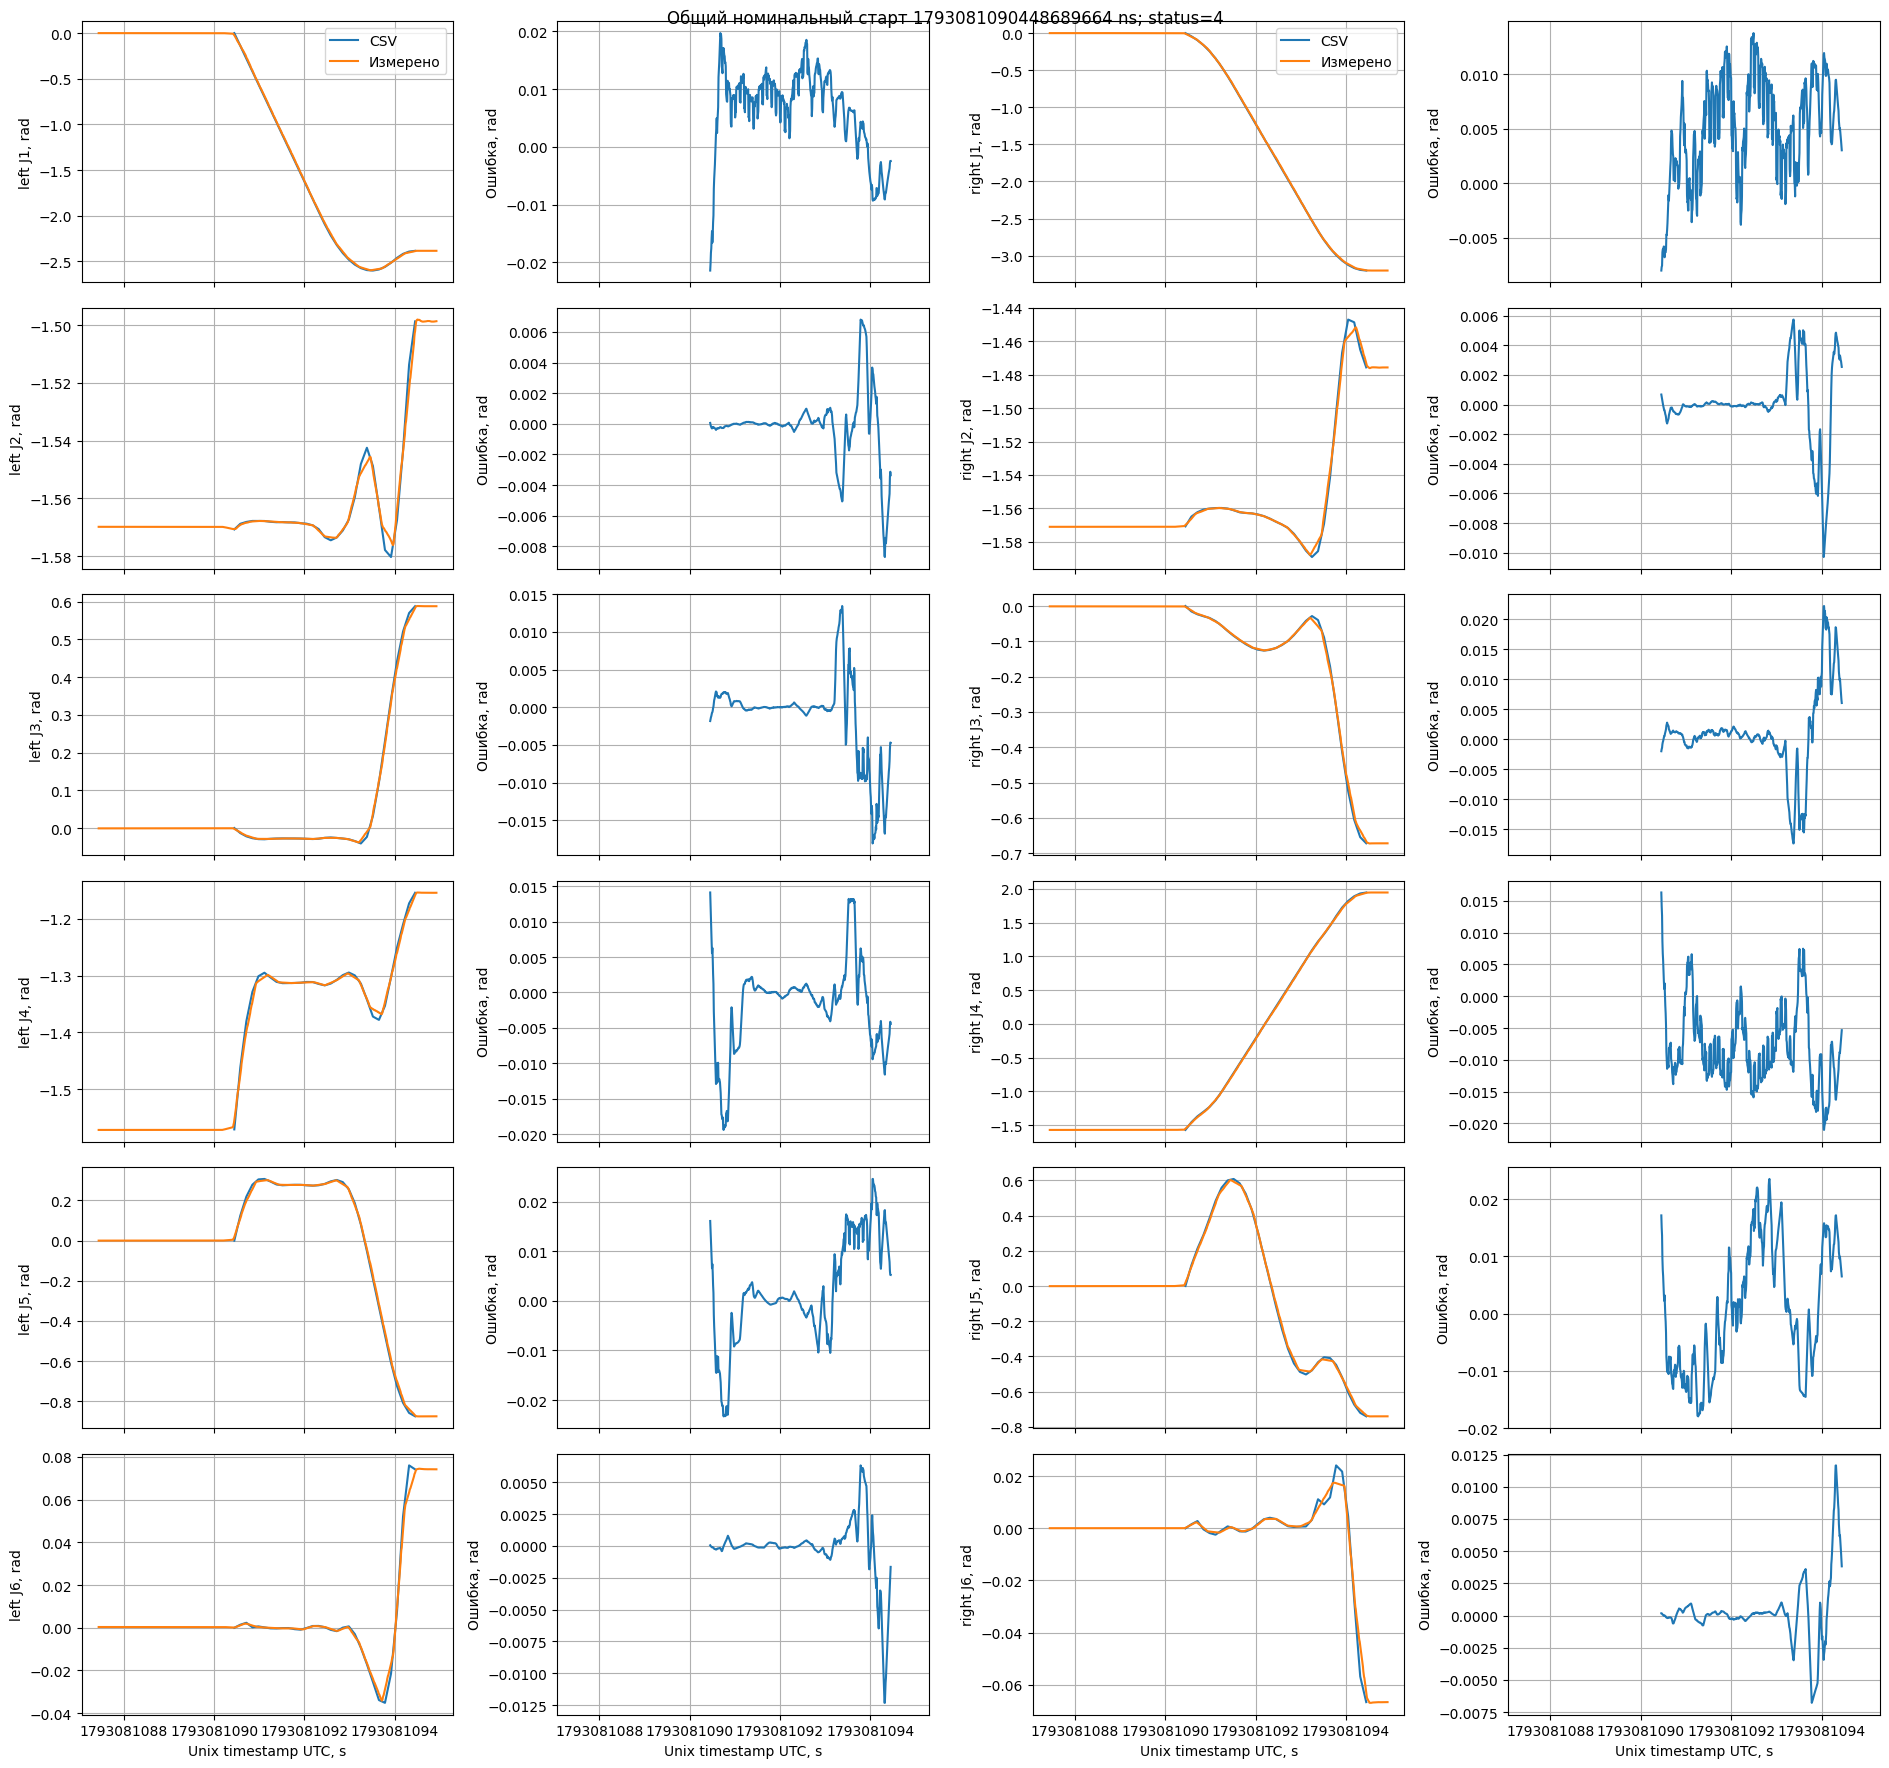

In [9]:
if not globals().get("run", {}).get("requested_start_stamp_ns"):
    raise RuntimeError("Сначала выполните CSV; подвод не анализируется как CSV")
analysis_run_id = None
start_ns = int(run["requested_start_stamp_ns"])
frames, metrics = {}, []
fig, axes = plt.subplots(6, 4, figsize=(19, 18), sharex=True)
for arm_index, arm in enumerate(ARMS):
    raw = pd.DataFrame(run["rows"][arm], columns=["stamp_ns", "receive_ns", *[f"q{j}" for j in range(1, 7)]])
    if raw.empty:
        raise RuntimeError(f"Нет измерений {arm}; анализ недоступен")
    if np.any(np.diff(raw.stamp_ns.to_numpy(dtype=np.int64)) < 0):
        raise RuntimeError(f"{arm}: timestamp идут назад; проверьте часы")
    raw = raw.drop_duplicates("stamp_ns").copy()
    elapsed = (raw.stamp_ns.to_numpy(dtype=np.int64) - start_ns)*1e-9
    raw["elapsed_s"] = elapsed
    measured = raw[[f"q{j}" for j in range(1, 7)]].to_numpy()
    target = run["q"][:, arm_index*6:(arm_index+1)*6]
    desired = np.column_stack([np.interp(elapsed, run["t"], target[:, j]) for j in range(6)])
    inside = (elapsed >= 0) & (elapsed <= run["t"][-1])
    if not inside.any():
        raise RuntimeError(f"{arm}: нет измерений внутри времени CSV")
    errors = measured-desired
    for j in range(6):
        raw[f"desired_q{j+1}"] = desired[:, j]
        raw[f"error_q{j+1}"] = np.where(inside, errors[:, j], np.nan)
        metrics.append({"arm": arm, "joint": JOINTS[arm_index*6+j], "samples": int(inside.sum()),
                        "rmse_rad": float(np.sqrt(np.mean(errors[inside, j]**2))),
                        "max_abs_rad": float(np.max(abs(errors[inside, j])))})
        ax, err = axes[j, arm_index*2:arm_index*2+2]
        ax.plot(start_ns*1e-9+run["t"], target[:, j], label="CSV")
        ax.plot(raw.stamp_ns.to_numpy()*1e-9, measured[:, j], label="Измерено")
        err.plot(raw.loc[inside, "stamp_ns"].to_numpy()*1e-9, errors[inside, j])
        ax.set_ylabel(f"{arm} J{j+1}, rad"); err.set_ylabel("Ошибка, rad")
        for axis in (ax, err):
            axis.grid(True); axis.ticklabel_format(axis="x", style="plain", useOffset=False)
    frames[arm] = raw
for ax in axes[-1]: ax.set_xlabel("Unix timestamp UTC, s")
axes[0, 0].legend(); axes[0, 2].legend()
fig.suptitle(f"Общий номинальный старт {start_ns} ns; status={run['status']}")
fig.tight_layout()
metrics = pd.DataFrame(metrics)
display(metrics)
analysis_run_id = run["run_id"]

## 7. Сохранение и отключение
Сохраняются исходные timestamp обеих рук, отправленные точки, параметры и график. Сначала отмените незавершённую цель; клиент не выключает питание.

In [10]:
SAVE = False
if SAVE:
    if globals().get("analysis_run_id") != run["run_id"]:
        raise RuntimeError("Сначала проанализируйте текущий запуск")
    import json
    from datetime import datetime, timezone
    out = ROOT / "results" / ("dual_ethernet_"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ"))
    out.mkdir(parents=True, exist_ok=False)
    for arm, frame in frames.items(): frame.to_csv(out/f"{arm}_feedback.csv", index=False)
    metrics.to_csv(out/"metrics.csv", index=False)
    sent = pd.DataFrame(run["q"], columns=JOINTS)
    sent.insert(0, "time_from_start_s", run["t"])
    sent.to_csv(out/"sent_trajectory.csv", index=False)
    scheduled = sent.copy()
    scheduled.insert(0, "stamp_ns", start_ns + np.rint(run["t"]*1e9).astype(np.int64))
    scheduled.to_csv(out/"scheduled_trajectory.csv", index=False)
    metadata = {k: run[k] for k in ("run_id", "source", "scale", "label", "interpolation", "driver",
        "request_stamp_ns", "requested_start_stamp_ns", "start_delay_s", "status", "error_code", "error_string")}
    metadata["goal_uuid"] = run.get("goal_uuid")
    metadata["measurement_timestamp"] = "Original per-arm joint_states header; dashboard read completion, not encoder clock"
    (out/"run.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
    fig.savefig(out/"tracking.png", dpi=150)
    print(out)

## 8. Случайная цель для обеих рук → RRTConnect → исполнение
Необязательная независимая ячейка: сначала выполните настройки, подключение и функции
(разделы 1–3), оставьте ROS-клиент открытым. `RUN_RANDOM=True` разрешает **одно** движение.
Генерируется совместная **суставная** цель (12 углов), не случайная Cartesian XYZ-точка:
по умолчанию каждый сустав отклоняется не более чем на 0.25 рад от текущей позы.
Проверяются лимиты, workspace и коллизии; путь строит RRTConnect для `both_arms`,
затем MoveIt исполняет его с медленными масштабами подвода. При отказе обхода проверок нет.
`RANDOM_SEED` воспроизводит выбор цели при том же старте; случайность самого RRTConnect не фиксируется.
Нулевая mock-поза вне workspace: сначала нужна допустимая исходная поза.
После движения старые предпросмотры подвода/CSV аннулируются; сам CSV и его результаты не меняются.


,joint,start_rad,target_rad,delta_rad
0,left_shoulder_joint,-2.38394,-1.162934,1.221006
1,left_upper_arm_joint,-1.49874,-1.991259,-0.492519
2,left_forearm_joint,0.58756,-2.393769,-2.981329
3,left_wrist_1_joint,-1.15438,-0.940933,0.213447
4,left_wrist_2_joint,-0.87431,-2.692042,-1.817732
5,left_wrist_3_joint,0.07421,1.729864,1.655654
6,right_shoulder_joint,-3.20132,-2.018890,1.182430
7,right_upper_arm_joint,-1.47558,-1.740465,-0.264885
8,right_forearm_joint,-0.67188,1.957343,2.629223
9,right_wrist_1_joint,1.94404,2.515005,0.570965


,arm,joint,samples,rmse_rad,max_abs_rad
0,left,left_shoulder_joint,1132,0.002325,0.006808
1,left,left_upper_arm_joint,1132,0.001441,0.003375
2,left,left_forearm_joint,1132,0.004100,0.011514
3,left,left_wrist_1_joint,1132,0.001537,0.003675
4,left,left_wrist_2_joint,1132,0.003171,0.007805
5,left,left_wrist_3_joint,1132,0.002331,0.004381
6,right,right_shoulder_joint,1132,0.001716,0.006698
7,right,right_upper_arm_joint,1132,0.000517,0.001809
8,right,right_forearm_joint,1132,0.002803,0.008590
9,right,right_wrist_1_joint,1132,0.003804,0.009941


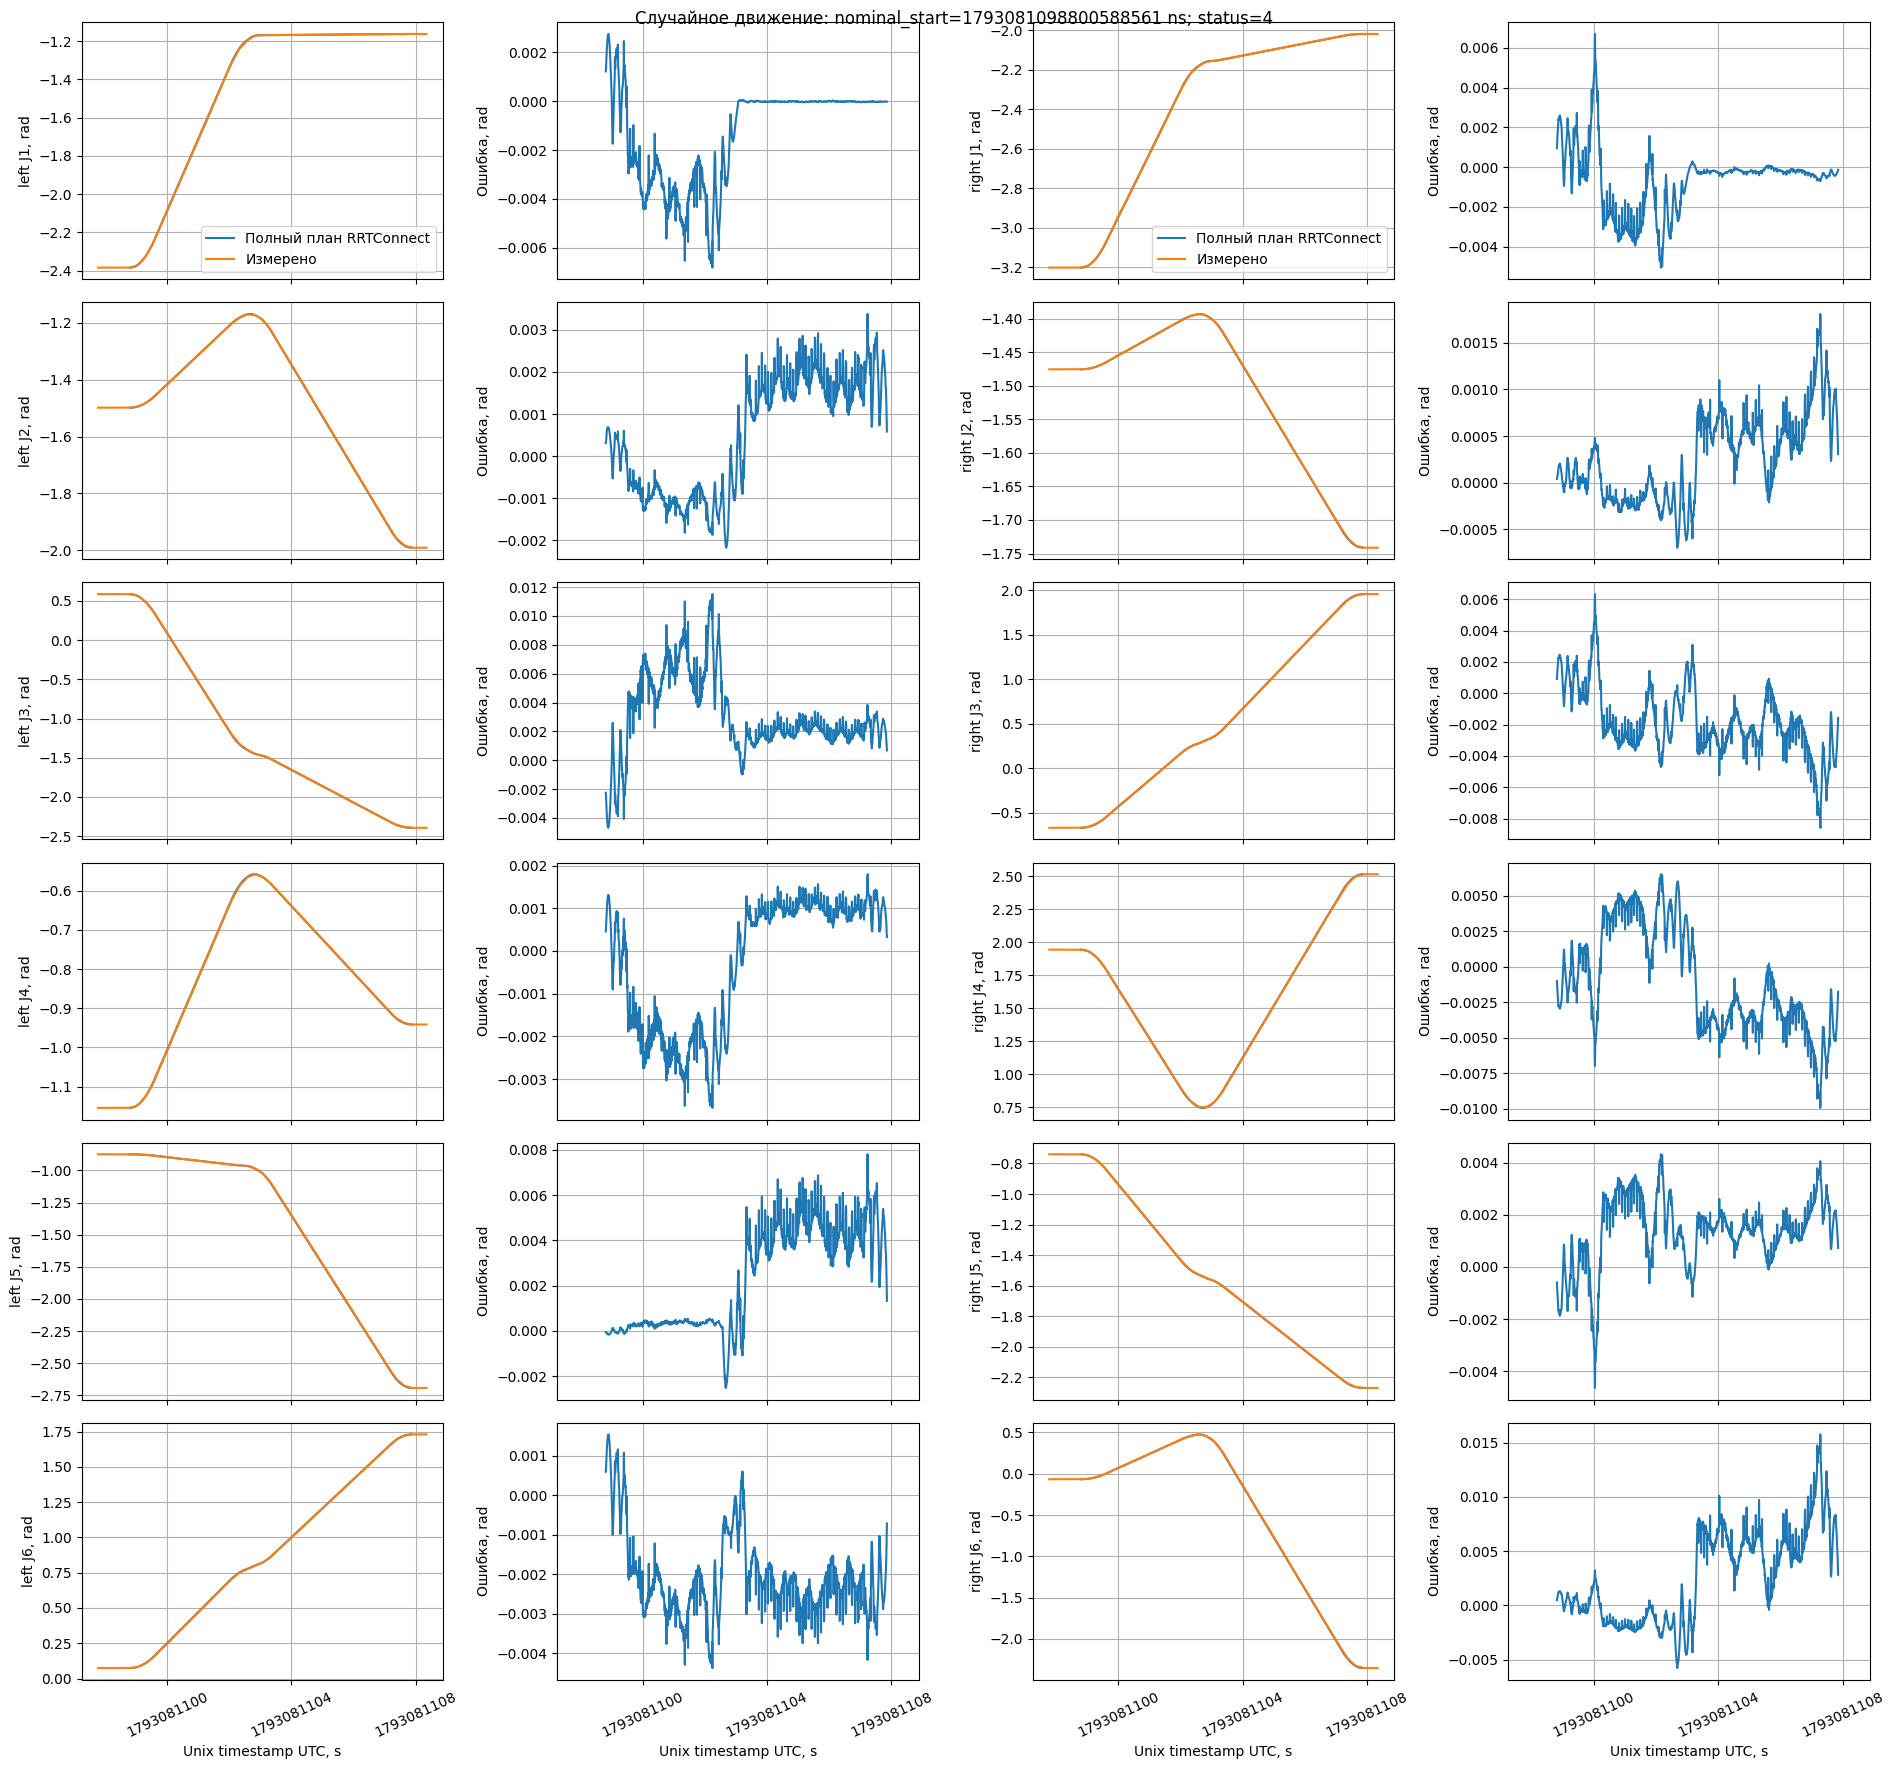

Обе руки достигли случайной цели; длительность плана 9.063 s.
CSV не запускался. Для возврата к его началу заново выполните ячейки подвода.


,joint,start_rad,target_rad,delta_rad
0,left_shoulder_joint,-1.16236,0.453601,1.615961
1,left_upper_arm_joint,-1.99087,0.310378,2.301248
2,left_forearm_joint,-2.39414,-1.988900,0.405240
3,left_wrist_1_joint,-0.94152,-2.921060,-1.979540
4,left_wrist_2_joint,-2.69235,-1.050488,1.641862
5,left_wrist_3_joint,1.72970,3.521156,1.791456
6,right_shoulder_joint,-2.01947,-2.219971,-0.200501
7,right_upper_arm_joint,-1.74130,-1.605738,0.135562
8,right_forearm_joint,1.95661,-0.070993,-2.027603
9,right_wrist_1_joint,2.51583,2.919090,0.403260


,arm,joint,samples,rmse_rad,max_abs_rad
0,left,left_shoulder_joint,585,0.004317,0.009078
1,left,left_upper_arm_joint,585,0.006115,0.013002
2,left,left_forearm_joint,585,0.001077,0.002226
3,left,left_wrist_1_joint,585,0.006121,0.012002
4,left,left_wrist_2_joint,585,0.005078,0.009979
5,left,left_wrist_3_joint,585,0.005543,0.010941
6,right,right_shoulder_joint,585,0.000412,0.000922
7,right,right_upper_arm_joint,585,0.000299,0.000635
8,right,right_forearm_joint,585,0.004156,0.009089
9,right,right_wrist_1_joint,585,0.001002,0.002065


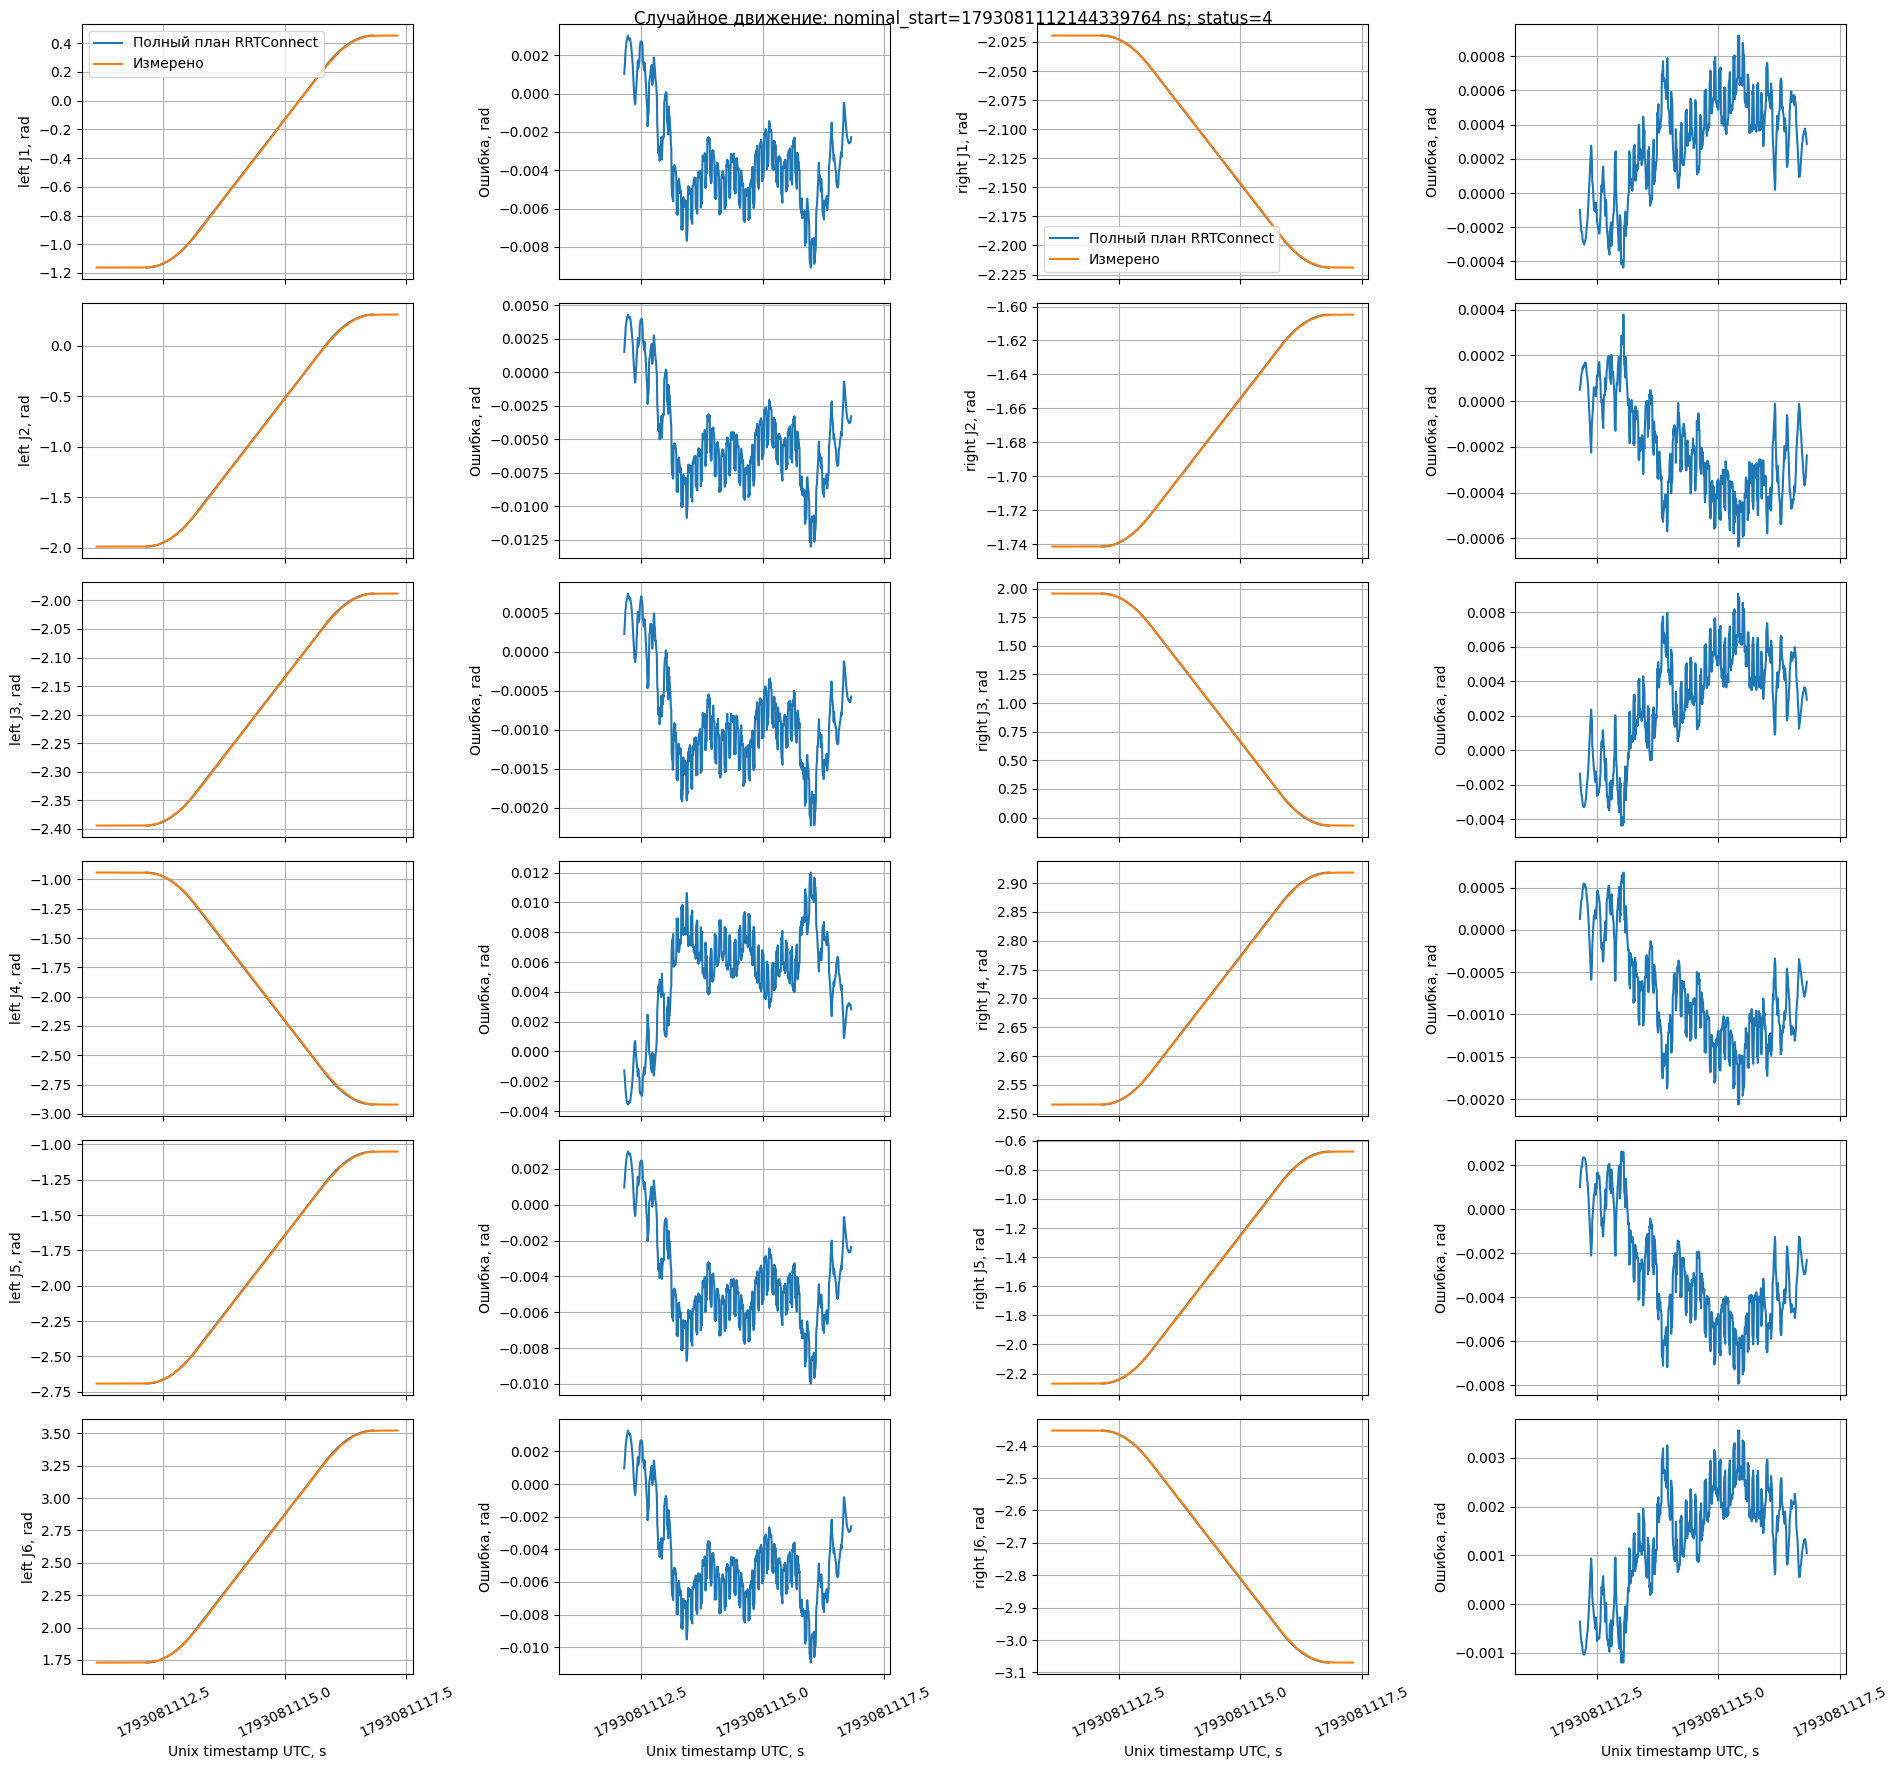

Обе руки достигли случайной цели; длительность плана 4.683 s.
CSV не запускался. Для возврата к его началу заново выполните ячейки подвода.


,joint,start_rad,target_rad,delta_rad
0,left_shoulder_joint,0.45358,0.106162,-0.347418
1,left_upper_arm_joint,0.31109,-2.039097,-2.350187
2,left_forearm_joint,-1.98798,0.384411,2.372391
3,left_wrist_1_joint,-2.92082,-1.448467,1.472353
4,left_wrist_2_joint,-1.05069,-0.317217,0.733473
5,left_wrist_3_joint,3.52090,2.696736,-0.824164
6,right_shoulder_joint,-2.21900,-4.285242,-2.066242
7,right_upper_arm_joint,-1.60482,-0.626268,0.978552
8,right_forearm_joint,-0.07055,-0.768403,-0.697853
9,right_wrist_1_joint,2.91822,0.641080,-2.277140


,arm,joint,samples,rmse_rad,max_abs_rad
0,left,left_shoulder_joint,661,0.000637,0.001612
1,left,left_upper_arm_joint,661,0.004290,0.010943
2,left,left_forearm_joint,661,0.004360,0.011182
3,left,left_wrist_1_joint,661,0.003216,0.007507
4,left,left_wrist_2_joint,661,0.001605,0.003804
5,left,left_wrist_3_joint,661,0.001800,0.004217
6,right,right_shoulder_joint,661,0.003385,0.007860
7,right,right_upper_arm_joint,661,0.001587,0.003724
8,right,right_forearm_joint,661,0.001151,0.002671
9,right,right_wrist_1_joint,661,0.004388,0.009586


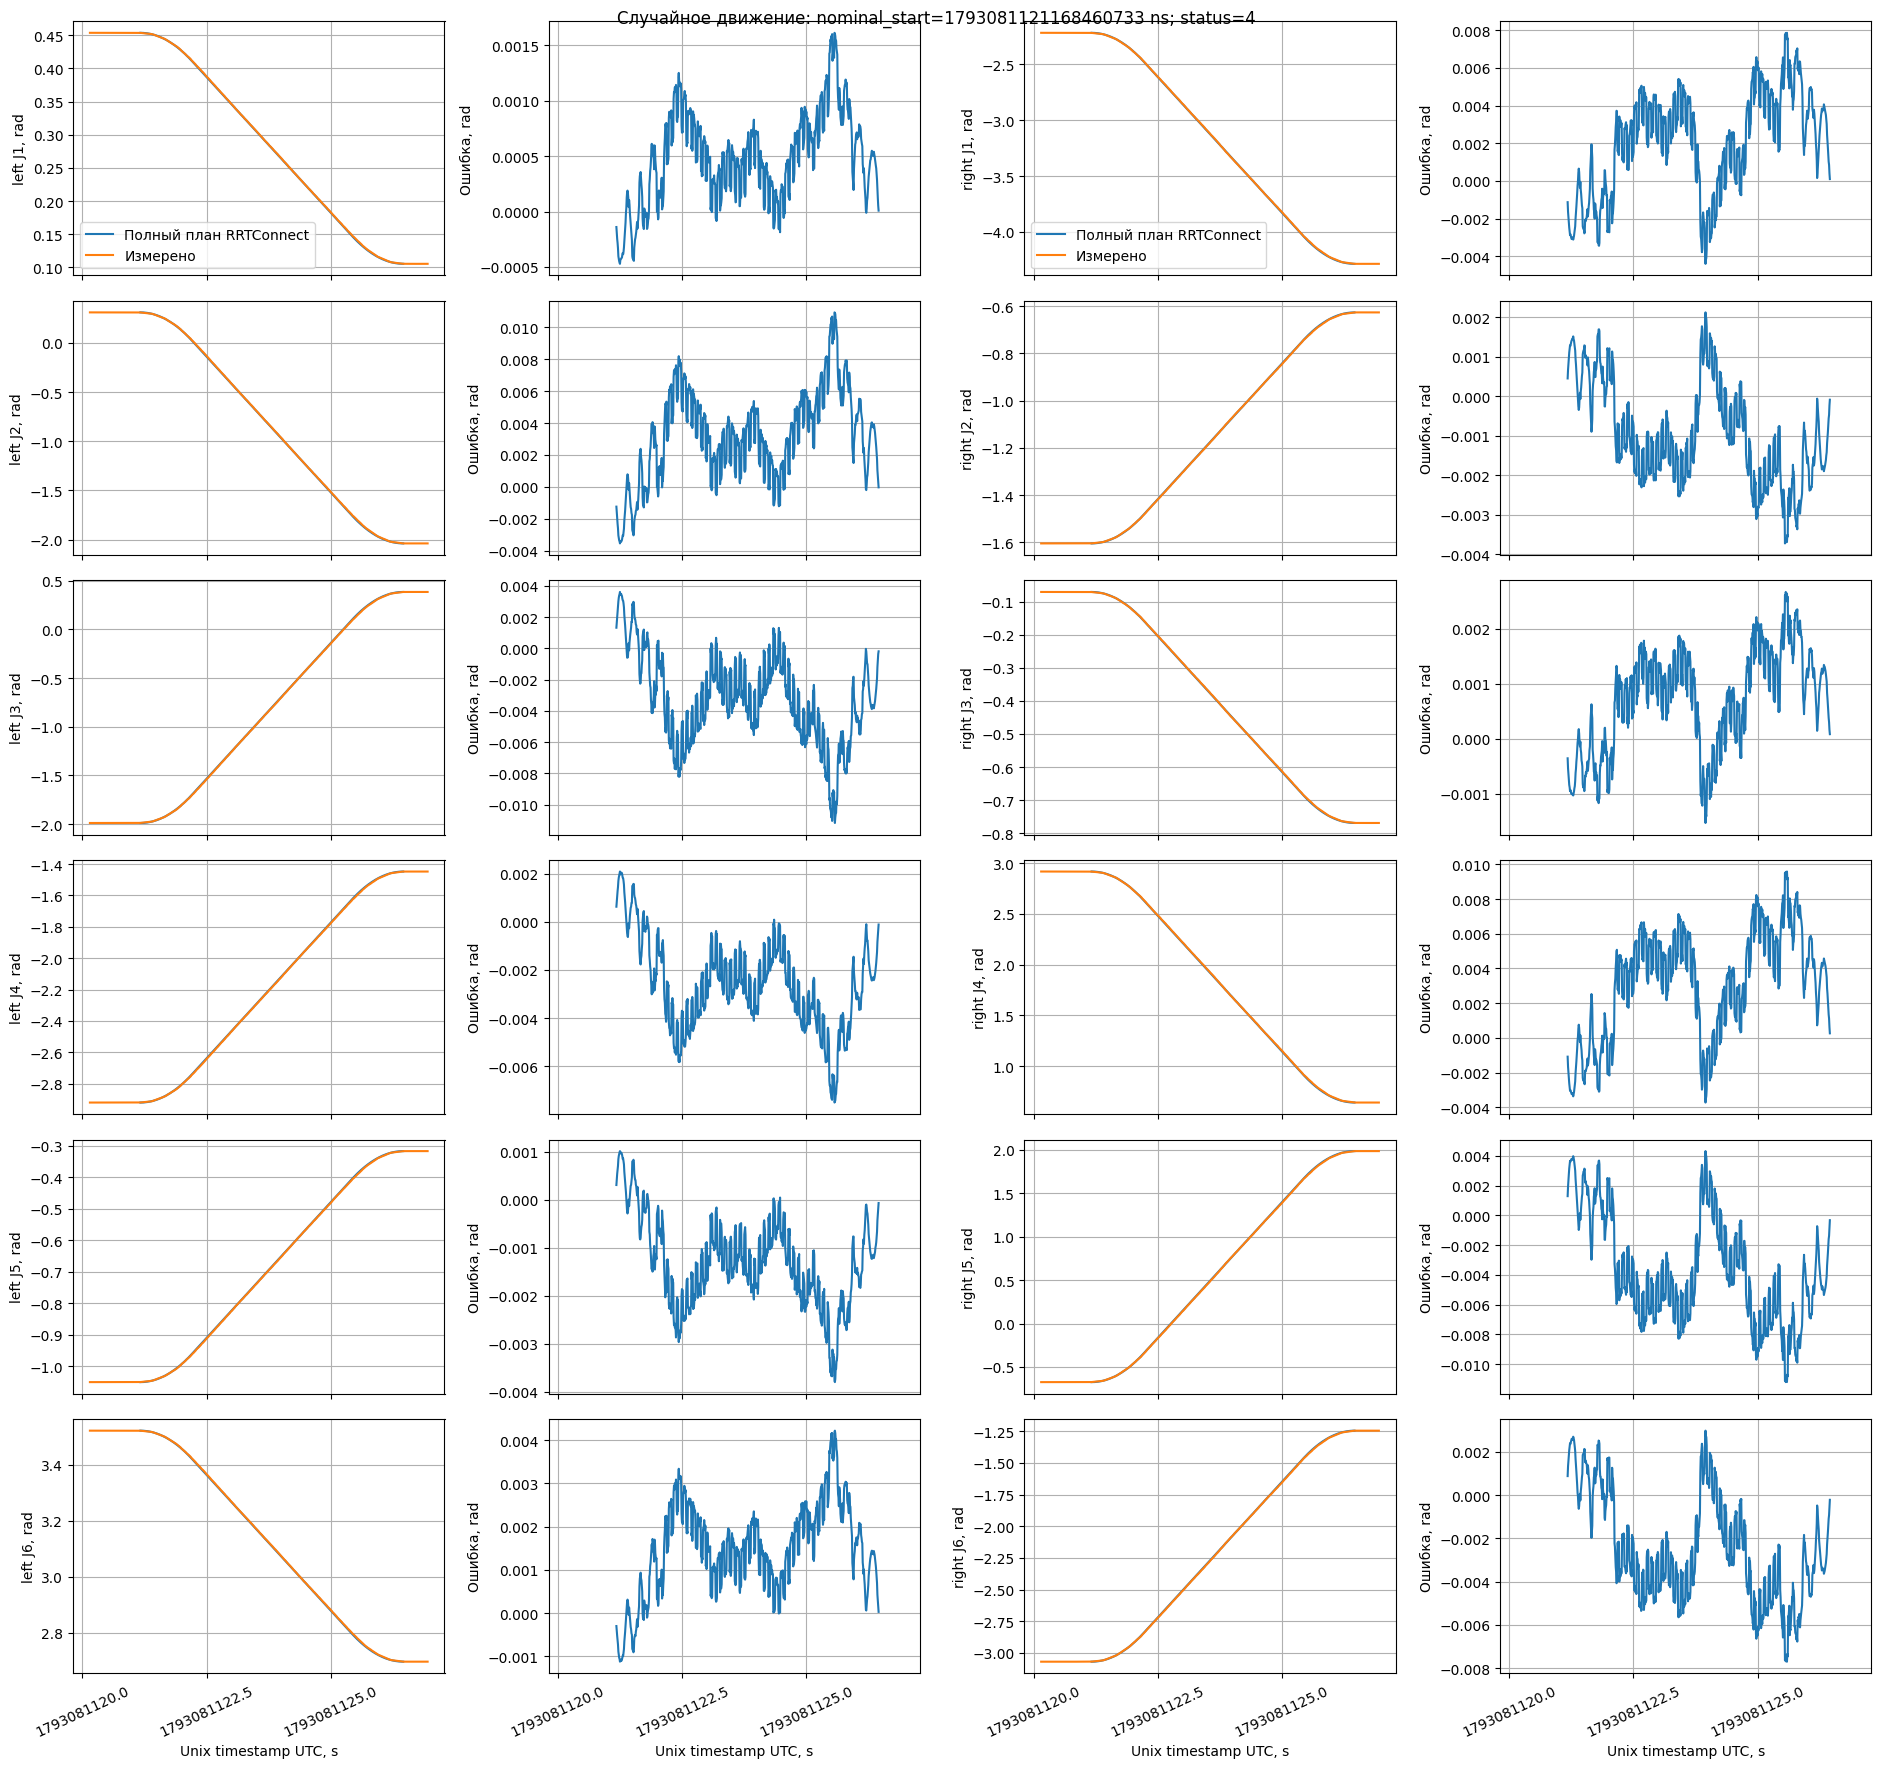

Обе руки достигли случайной цели; длительность плана 5.292 s.
CSV не запускался. Для возврата к его началу заново выполните ячейки подвода.


,joint,start_rad,target_rad,delta_rad
0,left_shoulder_joint,0.10550,-0.767909,-0.873409
1,left_upper_arm_joint,-2.03814,-1.439195,0.598945
2,left_forearm_joint,0.38538,0.624053,0.238673
3,left_wrist_1_joint,-1.44783,-0.471874,0.975956
4,left_wrist_2_joint,-0.31727,0.073777,0.391047
5,left_wrist_3_joint,2.69759,1.058926,-1.638664
6,right_shoulder_joint,-4.28576,-1.505612,2.780148
7,right_upper_arm_joint,-0.62621,-0.540690,0.085520
8,right_forearm_joint,-0.76899,-2.537181,-1.768191
9,right_wrist_1_joint,0.64080,-2.197525,-2.838325


,arm,joint,samples,rmse_rad,max_abs_rad
0,left,left_shoulder_joint,730,0.001539,0.003417
1,left,left_upper_arm_joint,730,0.001042,0.002262
2,left,left_forearm_joint,730,0.000416,0.000924
3,left,left_wrist_1_joint,730,0.002037,0.004327
4,left,left_wrist_2_joint,730,0.000816,0.001662
5,left,left_wrist_3_joint,730,0.003418,0.007162
6,right,right_shoulder_joint,730,0.004691,0.010205
7,right,right_upper_arm_joint,730,0.000156,0.000333
8,right,right_forearm_joint,730,0.002968,0.006524
9,right,right_wrist_1_joint,730,0.005730,0.011620


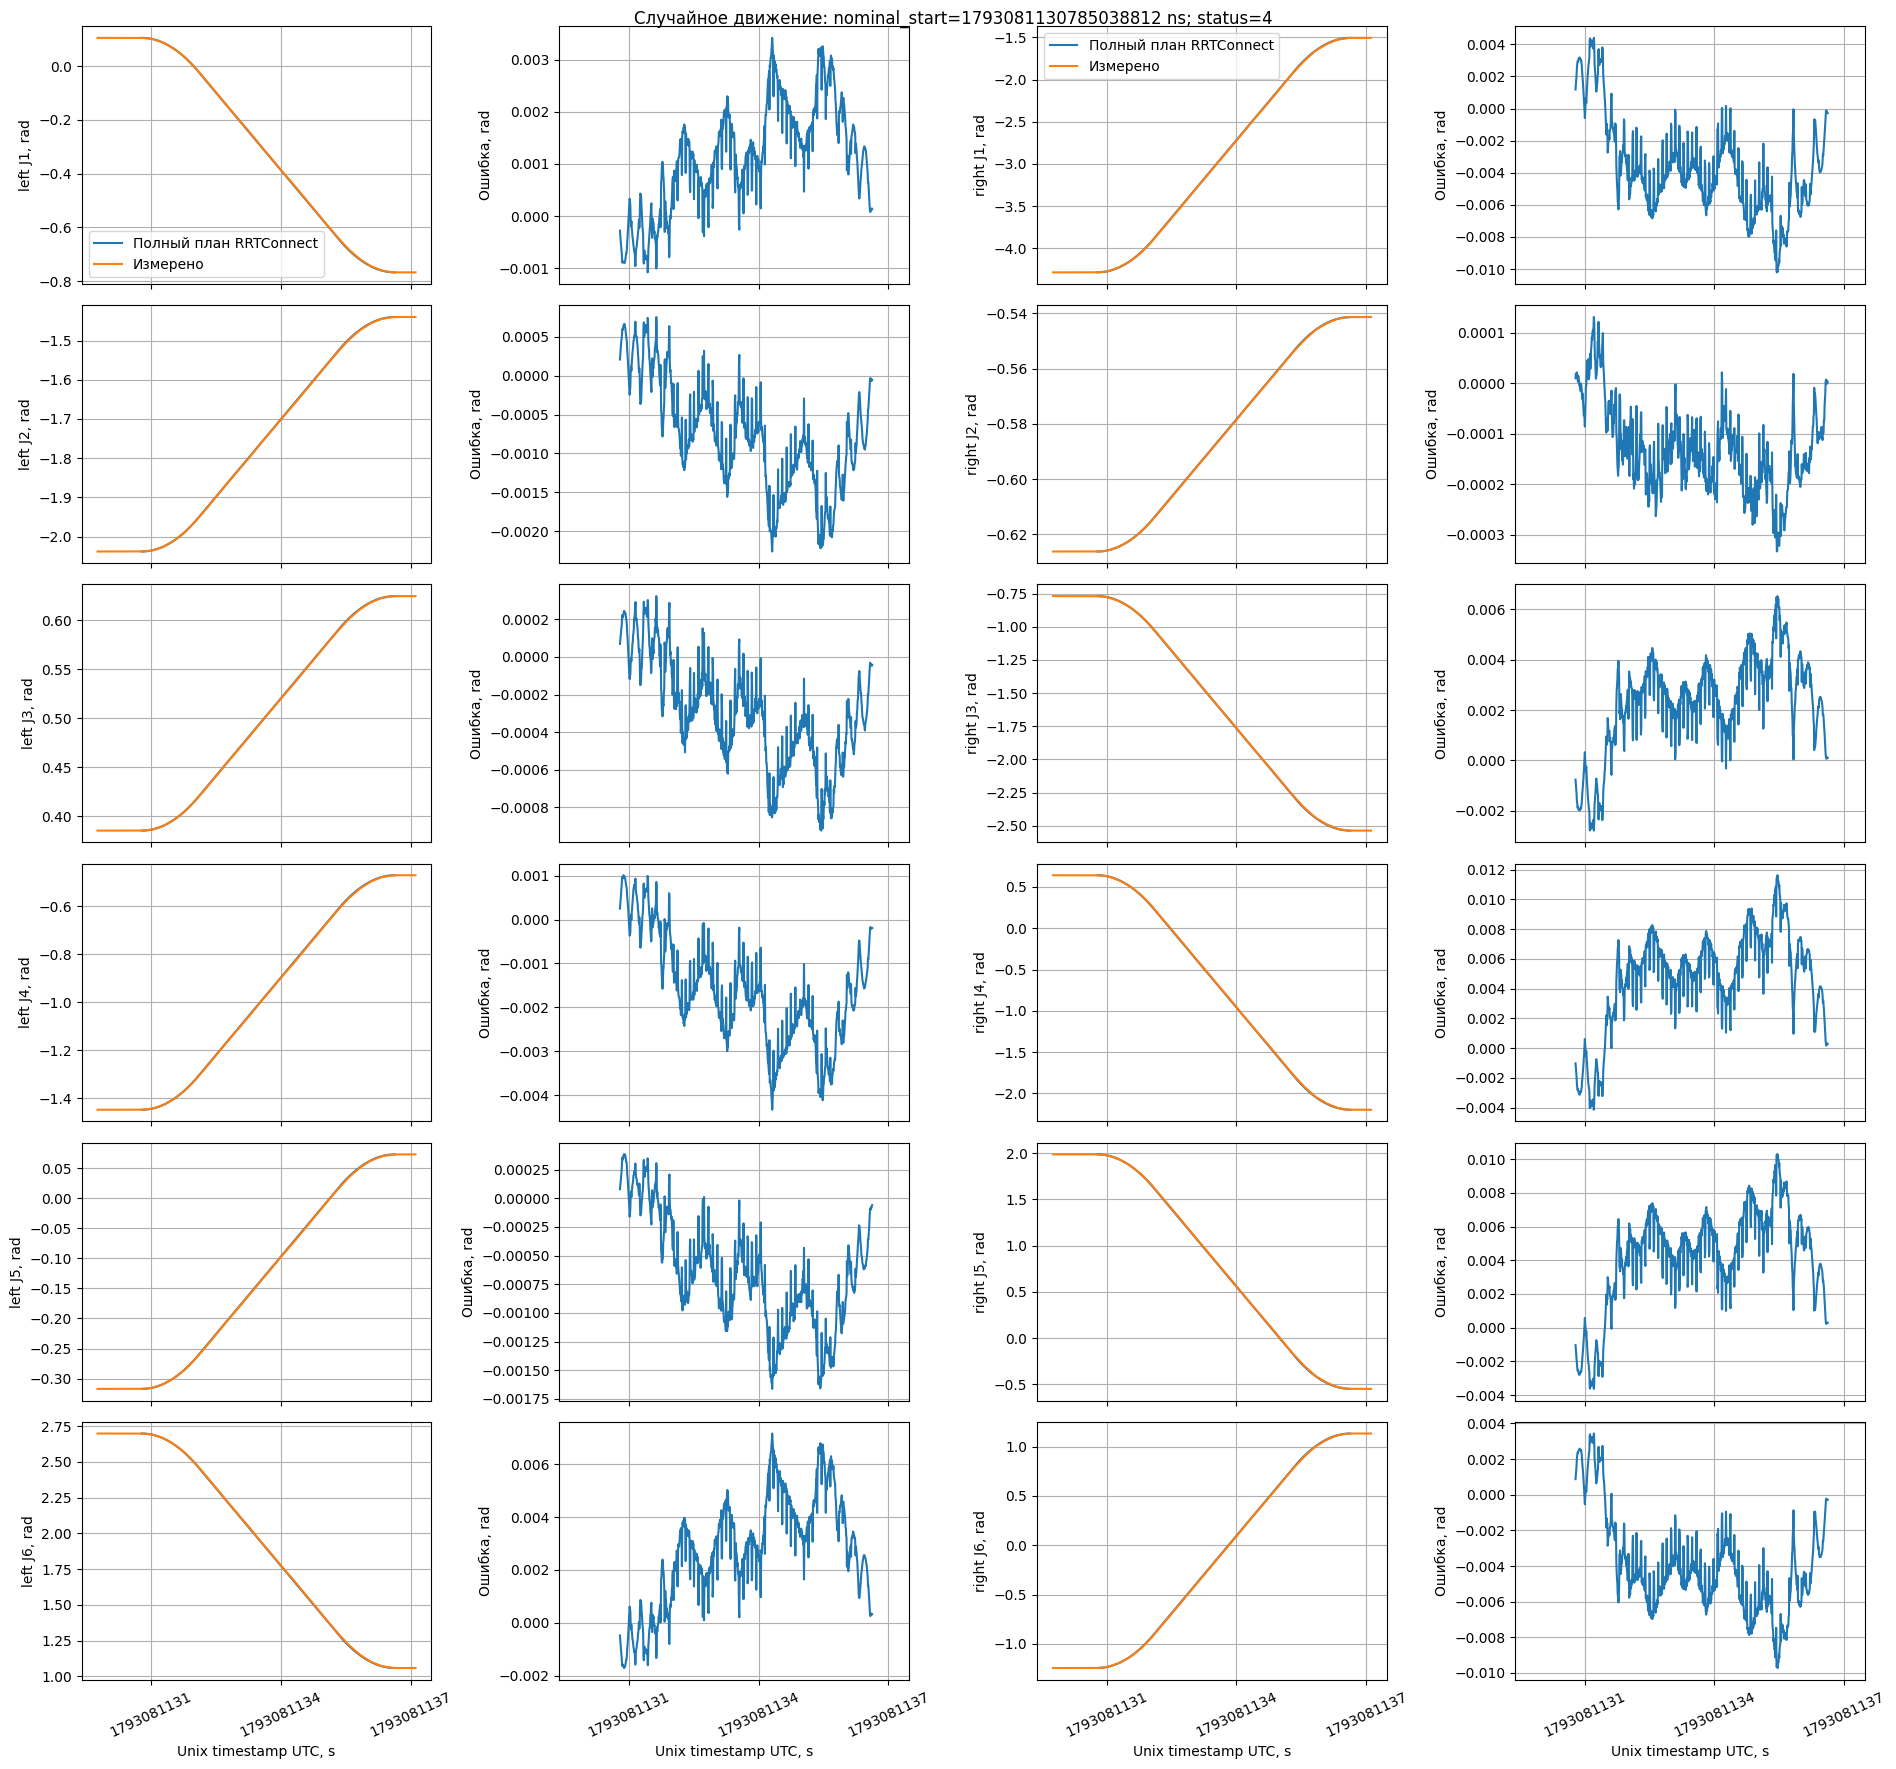

Обе руки достигли случайной цели; длительность плана 5.847 s.
CSV не запускался. Для возврата к его началу заново выполните ячейки подвода.


,joint,start_rad,target_rad,delta_rad
0,left_shoulder_joint,-0.76765,0.795817,1.563467
1,left_upper_arm_joint,-1.43997,-2.369931,-0.929961
2,left_forearm_joint,0.62469,0.672813,0.048123
3,left_wrist_1_joint,-0.47138,-0.561621,-0.090241
4,left_wrist_2_joint,0.07343,-2.947354,-3.020784
5,left_wrist_3_joint,1.05887,-1.509199,-2.568069
6,right_shoulder_joint,-1.50575,1.141632,2.647382
7,right_upper_arm_joint,-0.54139,-1.729586,-1.188196
8,right_forearm_joint,-2.53696,-2.462738,0.074222
9,right_wrist_1_joint,-2.19687,-0.831841,1.365029


,arm,joint,samples,rmse_rad,max_abs_rad
0,left,left_shoulder_joint,750,0.003350,0.006758
1,left,left_upper_arm_joint,750,0.001972,0.003983
2,left,left_forearm_joint,750,0.000118,0.000240
3,left,left_wrist_1_joint,750,0.000223,0.000445
4,left,left_wrist_2_joint,750,0.007421,0.014318
5,left,left_wrist_3_joint,750,0.006306,0.012175
6,right,right_shoulder_joint,750,0.003635,0.009054
7,right,right_upper_arm_joint,750,0.001617,0.004054
8,right,right_forearm_joint,750,0.000100,0.000255
9,right,right_wrist_1_joint,750,0.002211,0.005278


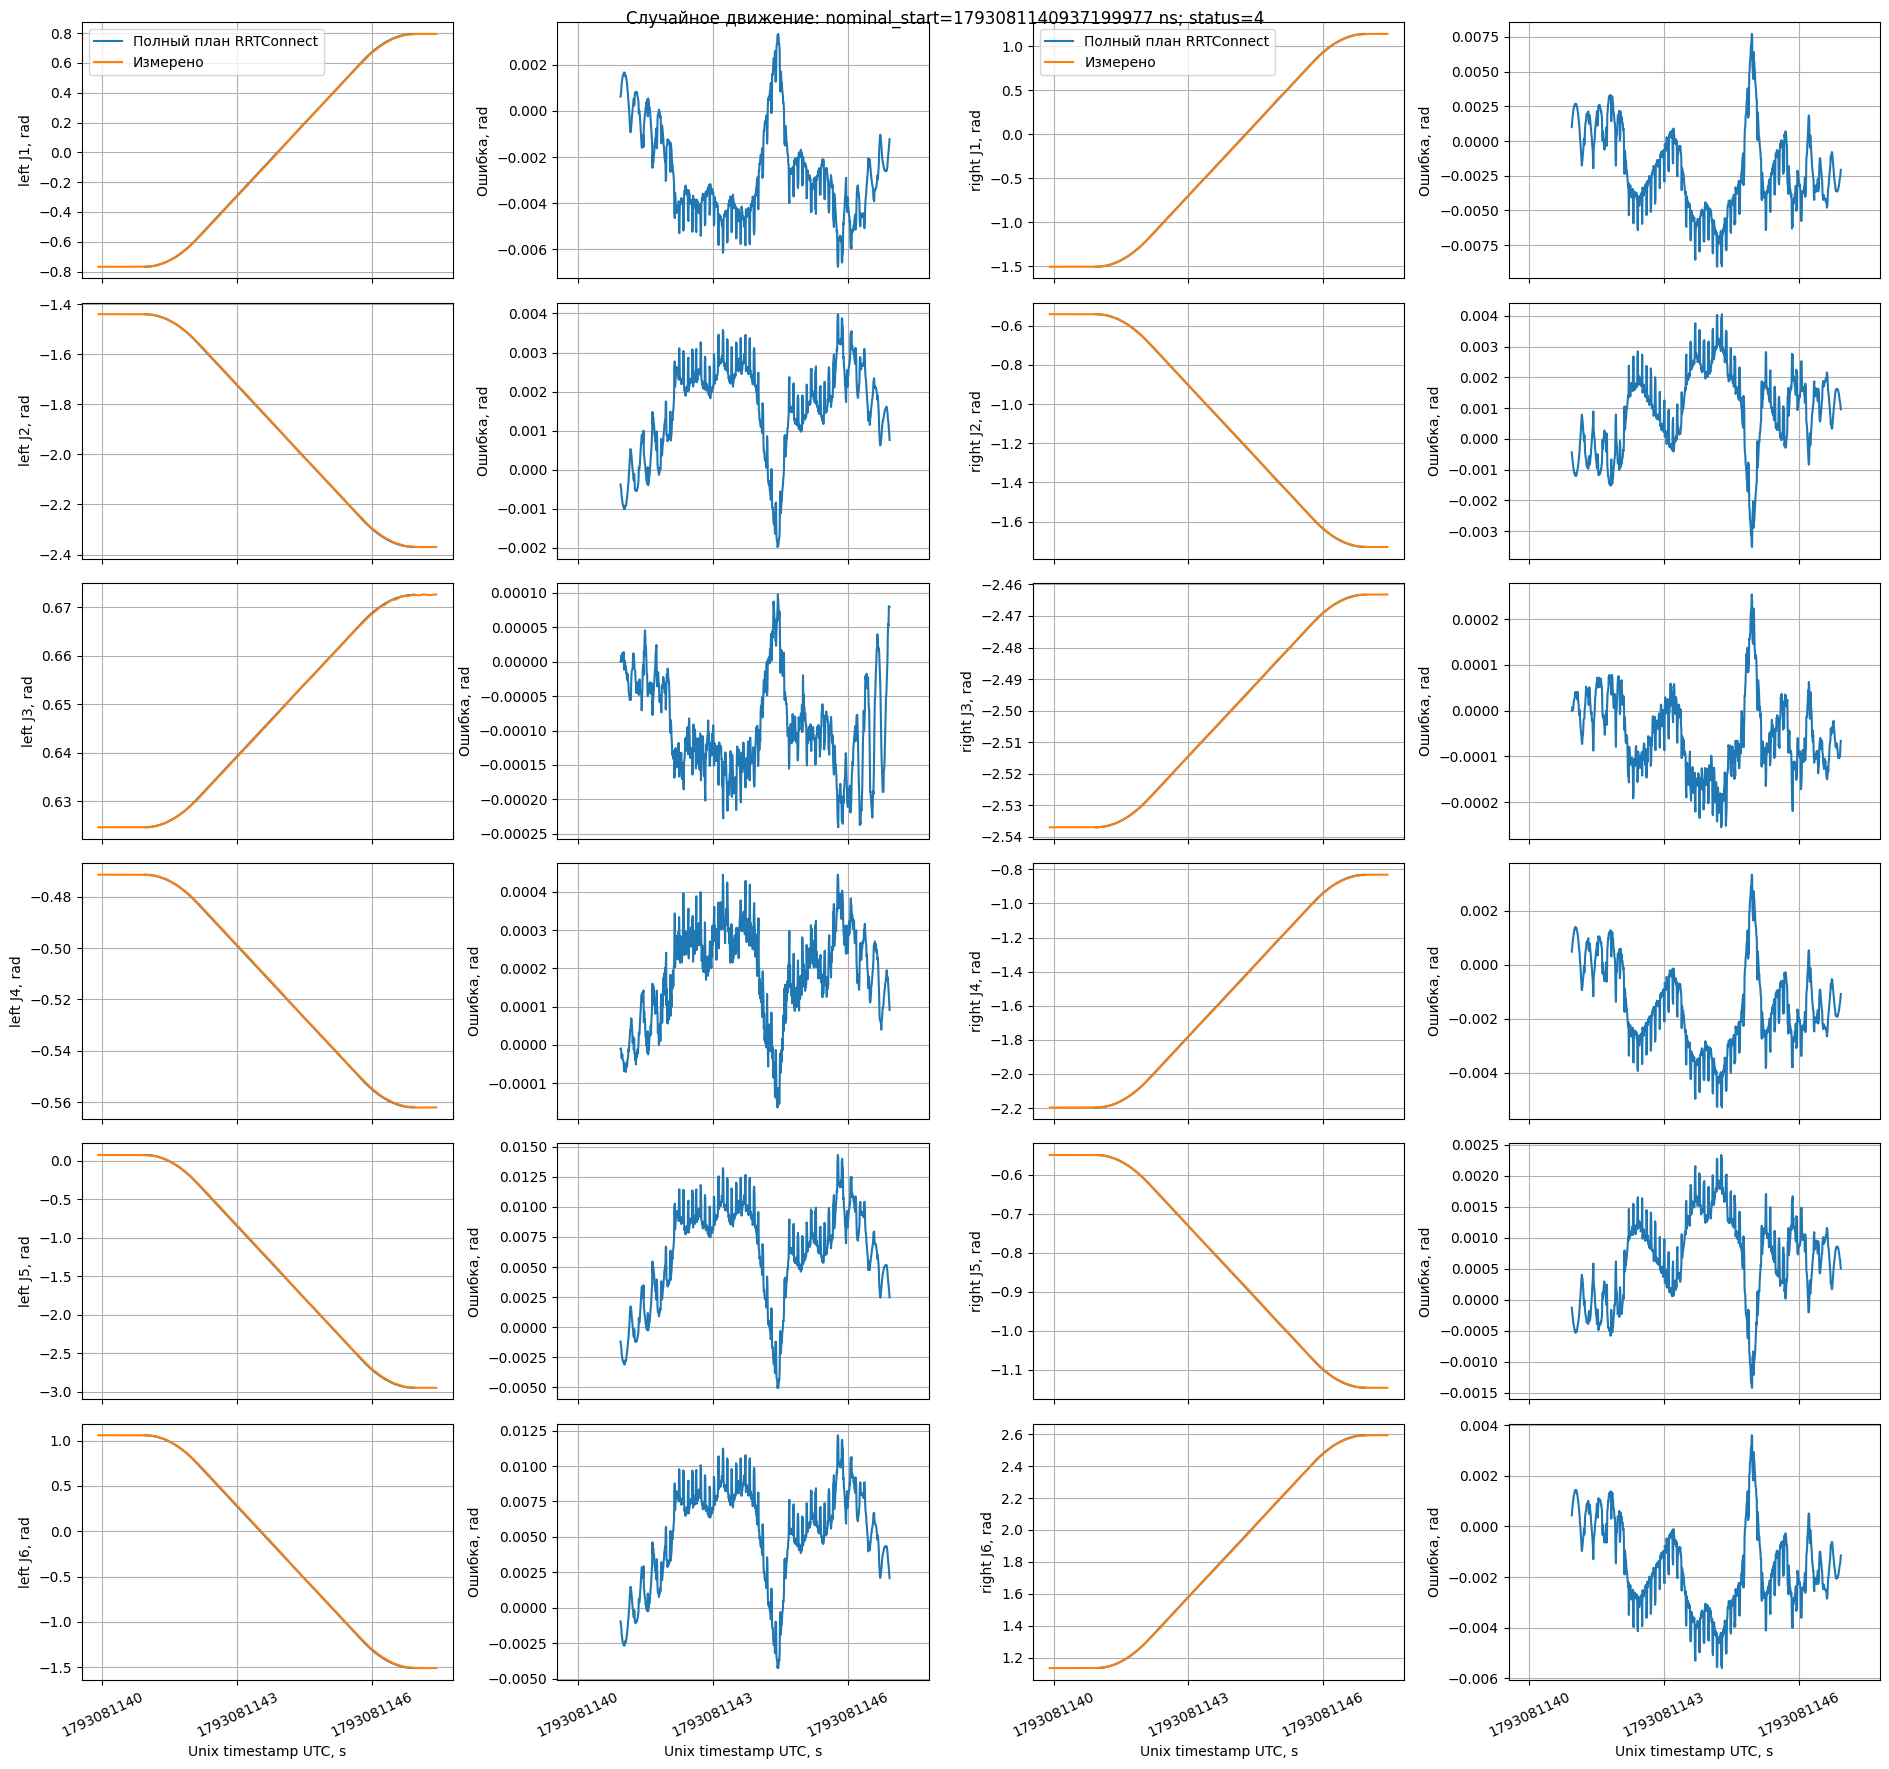

Обе руки достигли случайной цели; длительность плана 6.002 s.
CSV не запускался. Для возврата к его началу заново выполните ячейки подвода.


,joint,start_rad,target_rad,delta_rad
0,left_shoulder_joint,0.79492,2.489440,1.694520
1,left_upper_arm_joint,-2.36975,-2.240152,0.129598
2,left_forearm_joint,0.67250,1.989964,1.317464
3,left_wrist_1_joint,-0.56206,-2.744514,-2.182454
4,left_wrist_2_joint,-2.94774,-0.452966,2.494774
5,left_wrist_3_joint,-1.50962,-2.949959,-1.440339
6,right_shoulder_joint,1.14131,0.079151,-1.062159
7,right_upper_arm_joint,-1.72935,-0.805676,0.923674
8,right_forearm_joint,-2.46322,-2.676070,-0.212850
9,right_wrist_1_joint,-0.83174,0.573894,1.405634


,arm,joint,samples,rmse_rad,max_abs_rad
0,left,left_shoulder_joint,612,0.004247,0.007928
1,left,left_upper_arm_joint,612,0.000315,0.000608
2,left,left_forearm_joint,612,0.003277,0.006234
3,left,left_wrist_1_joint,612,0.006351,0.011157
4,left,left_wrist_2_joint,612,0.007270,0.012747
5,left,left_wrist_3_joint,612,0.004192,0.007351
6,right,right_shoulder_joint,612,0.002066,0.003830
7,right,right_upper_arm_joint,612,0.001794,0.003308
8,right,right_forearm_joint,612,0.000412,0.000780
9,right,right_wrist_1_joint,612,0.003298,0.005846


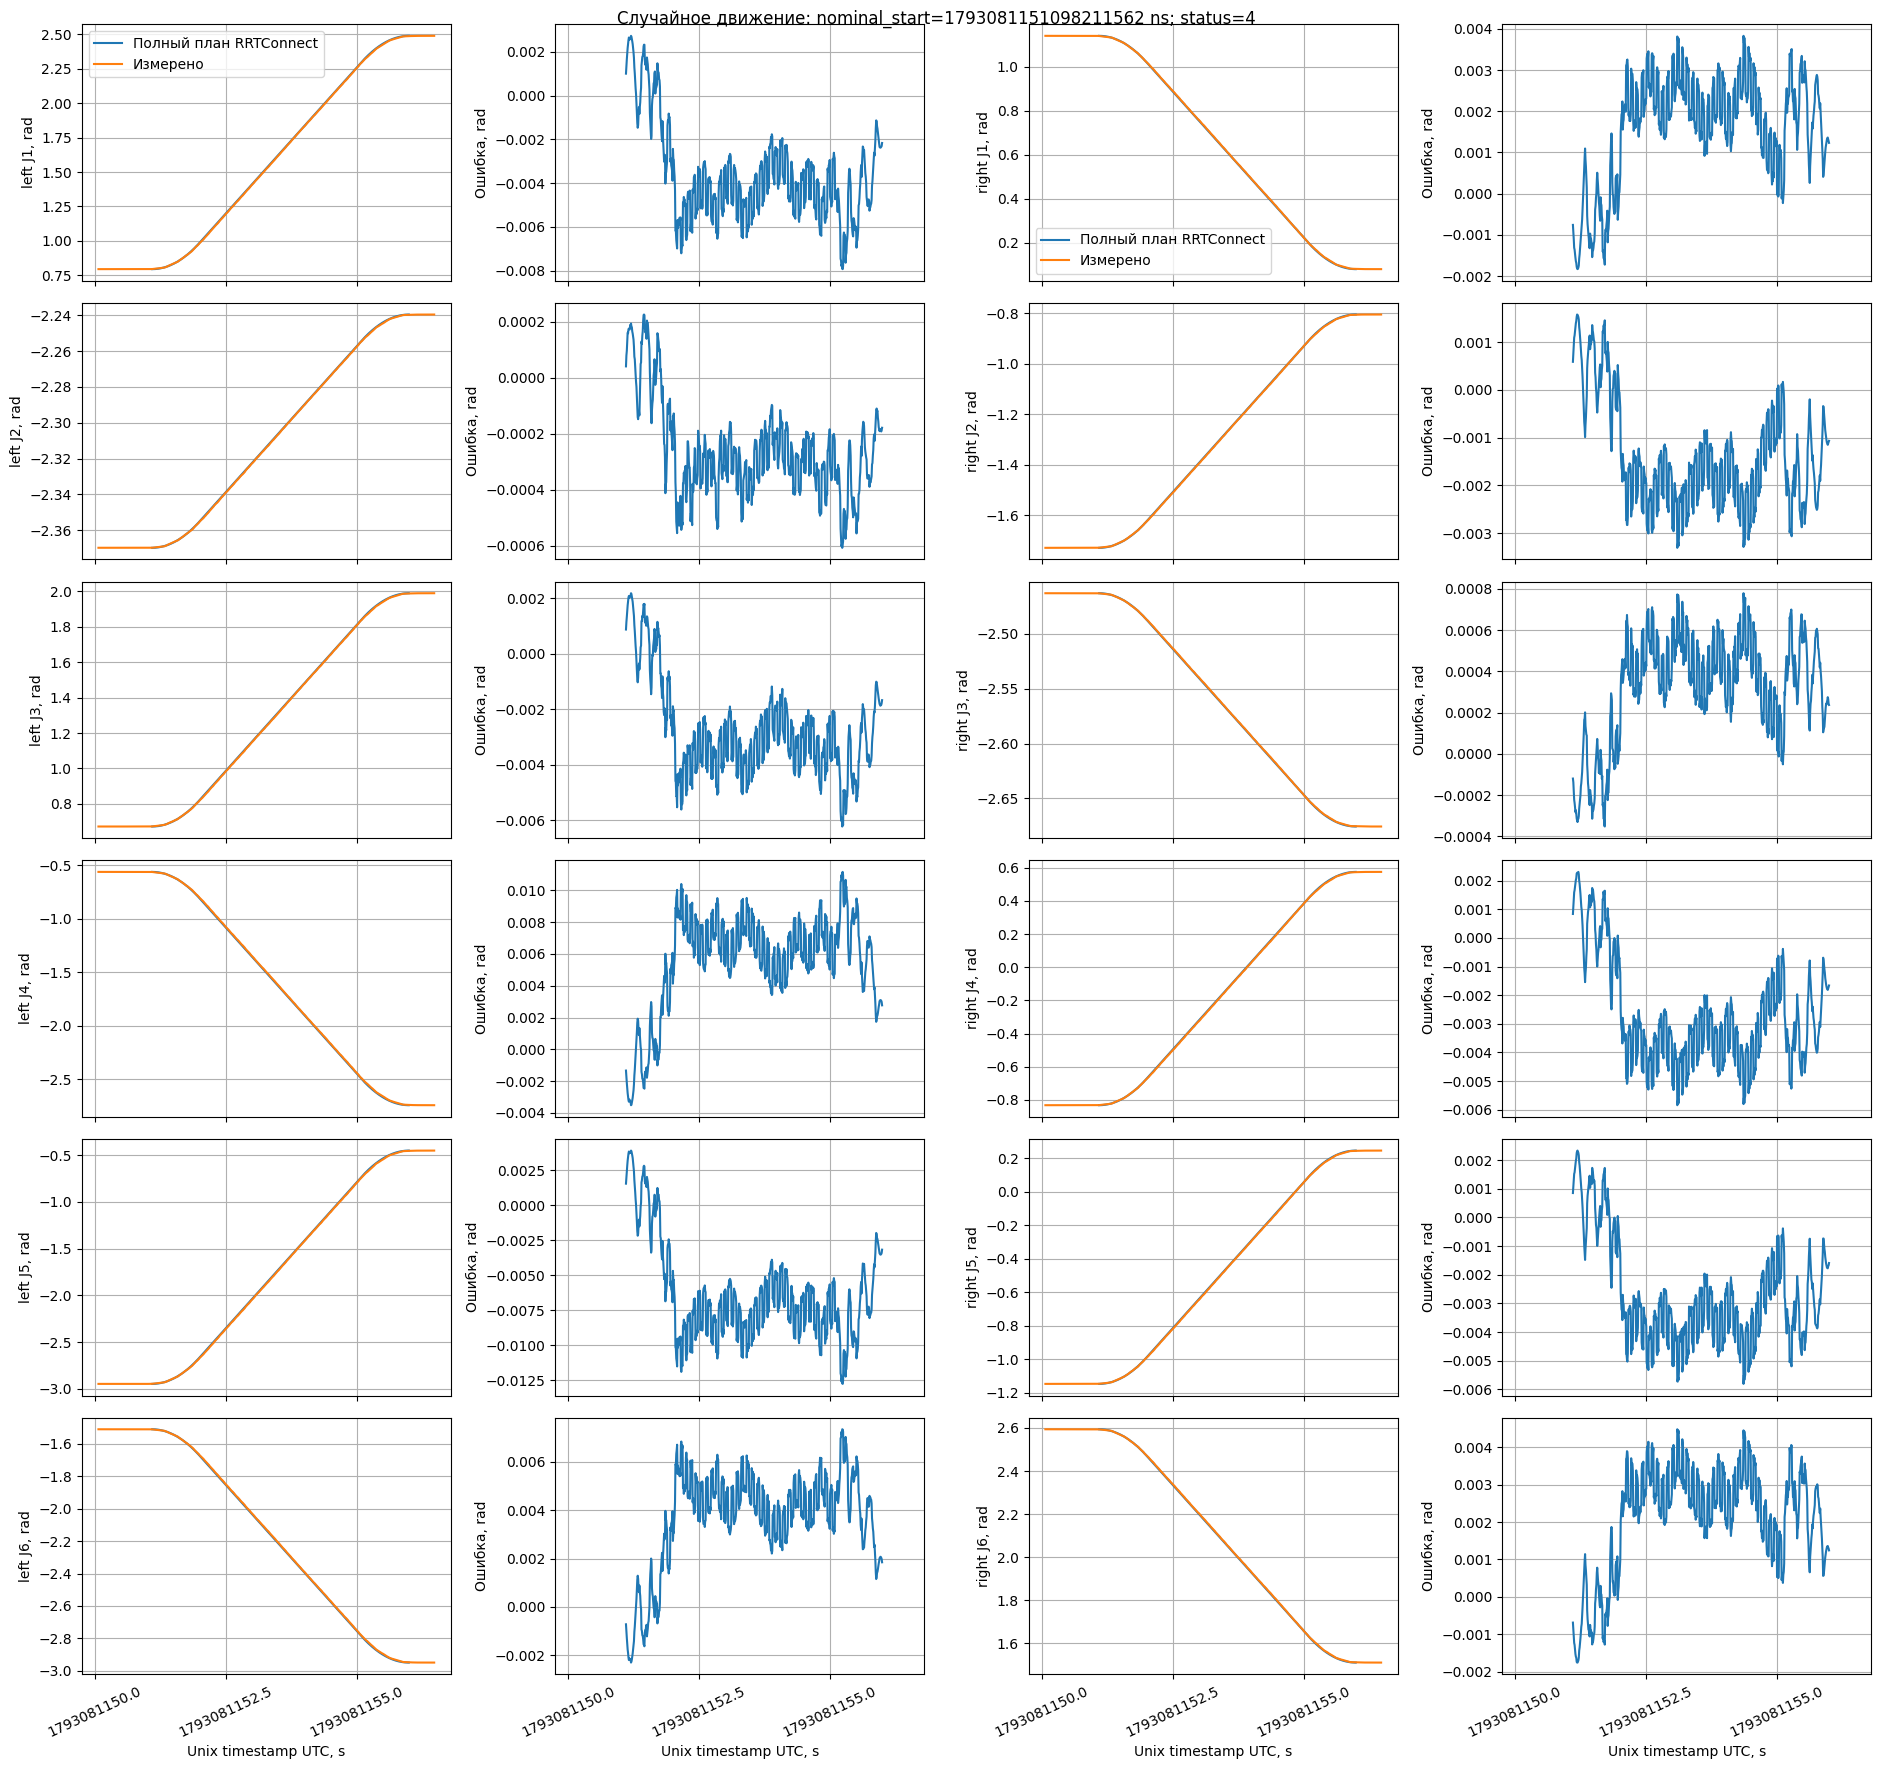

Обе руки достигли случайной цели; длительность плана 4.898 s.
CSV не запускался. Для возврата к его началу заново выполните ячейки подвода.


,joint,start_rad,target_rad,delta_rad
0,left_shoulder_joint,2.48950,3.299536,0.810036
1,left_upper_arm_joint,-2.23956,-2.534688,-0.295128
2,left_forearm_joint,1.98929,1.792669,-0.196621
3,left_wrist_1_joint,-2.74369,-0.727550,2.016140
4,left_wrist_2_joint,-0.45274,-0.602847,-0.150107
5,left_wrist_3_joint,-2.94918,-1.698860,1.250320
6,right_shoulder_joint,0.07868,0.044176,-0.034504
7,right_upper_arm_joint,-0.80569,0.155009,0.960699
8,right_forearm_joint,-2.67552,-2.006947,0.668573
9,right_wrist_1_joint,0.57446,-1.878713,-2.453173


Отмена запрошена; terminal: True — это НЕ аппаратный E-stop


,arm,joint,samples,rmse_rad,max_abs_rad
0,left,left_shoulder_joint,912,0.005002,0.011632
1,left,left_upper_arm_joint,912,0.001150,0.002953
2,left,left_forearm_joint,912,0.001075,0.002573
3,left,left_wrist_1_joint,912,0.004905,0.012754
4,left,left_wrist_2_joint,912,0.000470,0.001192
5,left,left_wrist_3_joint,912,0.004736,0.012006
6,right,right_shoulder_joint,912,0.000042,0.000114
7,right,right_upper_arm_joint,912,0.001436,0.004961
8,right,right_forearm_joint,912,0.001109,0.003727
9,right,right_wrist_1_joint,912,0.003285,0.010425


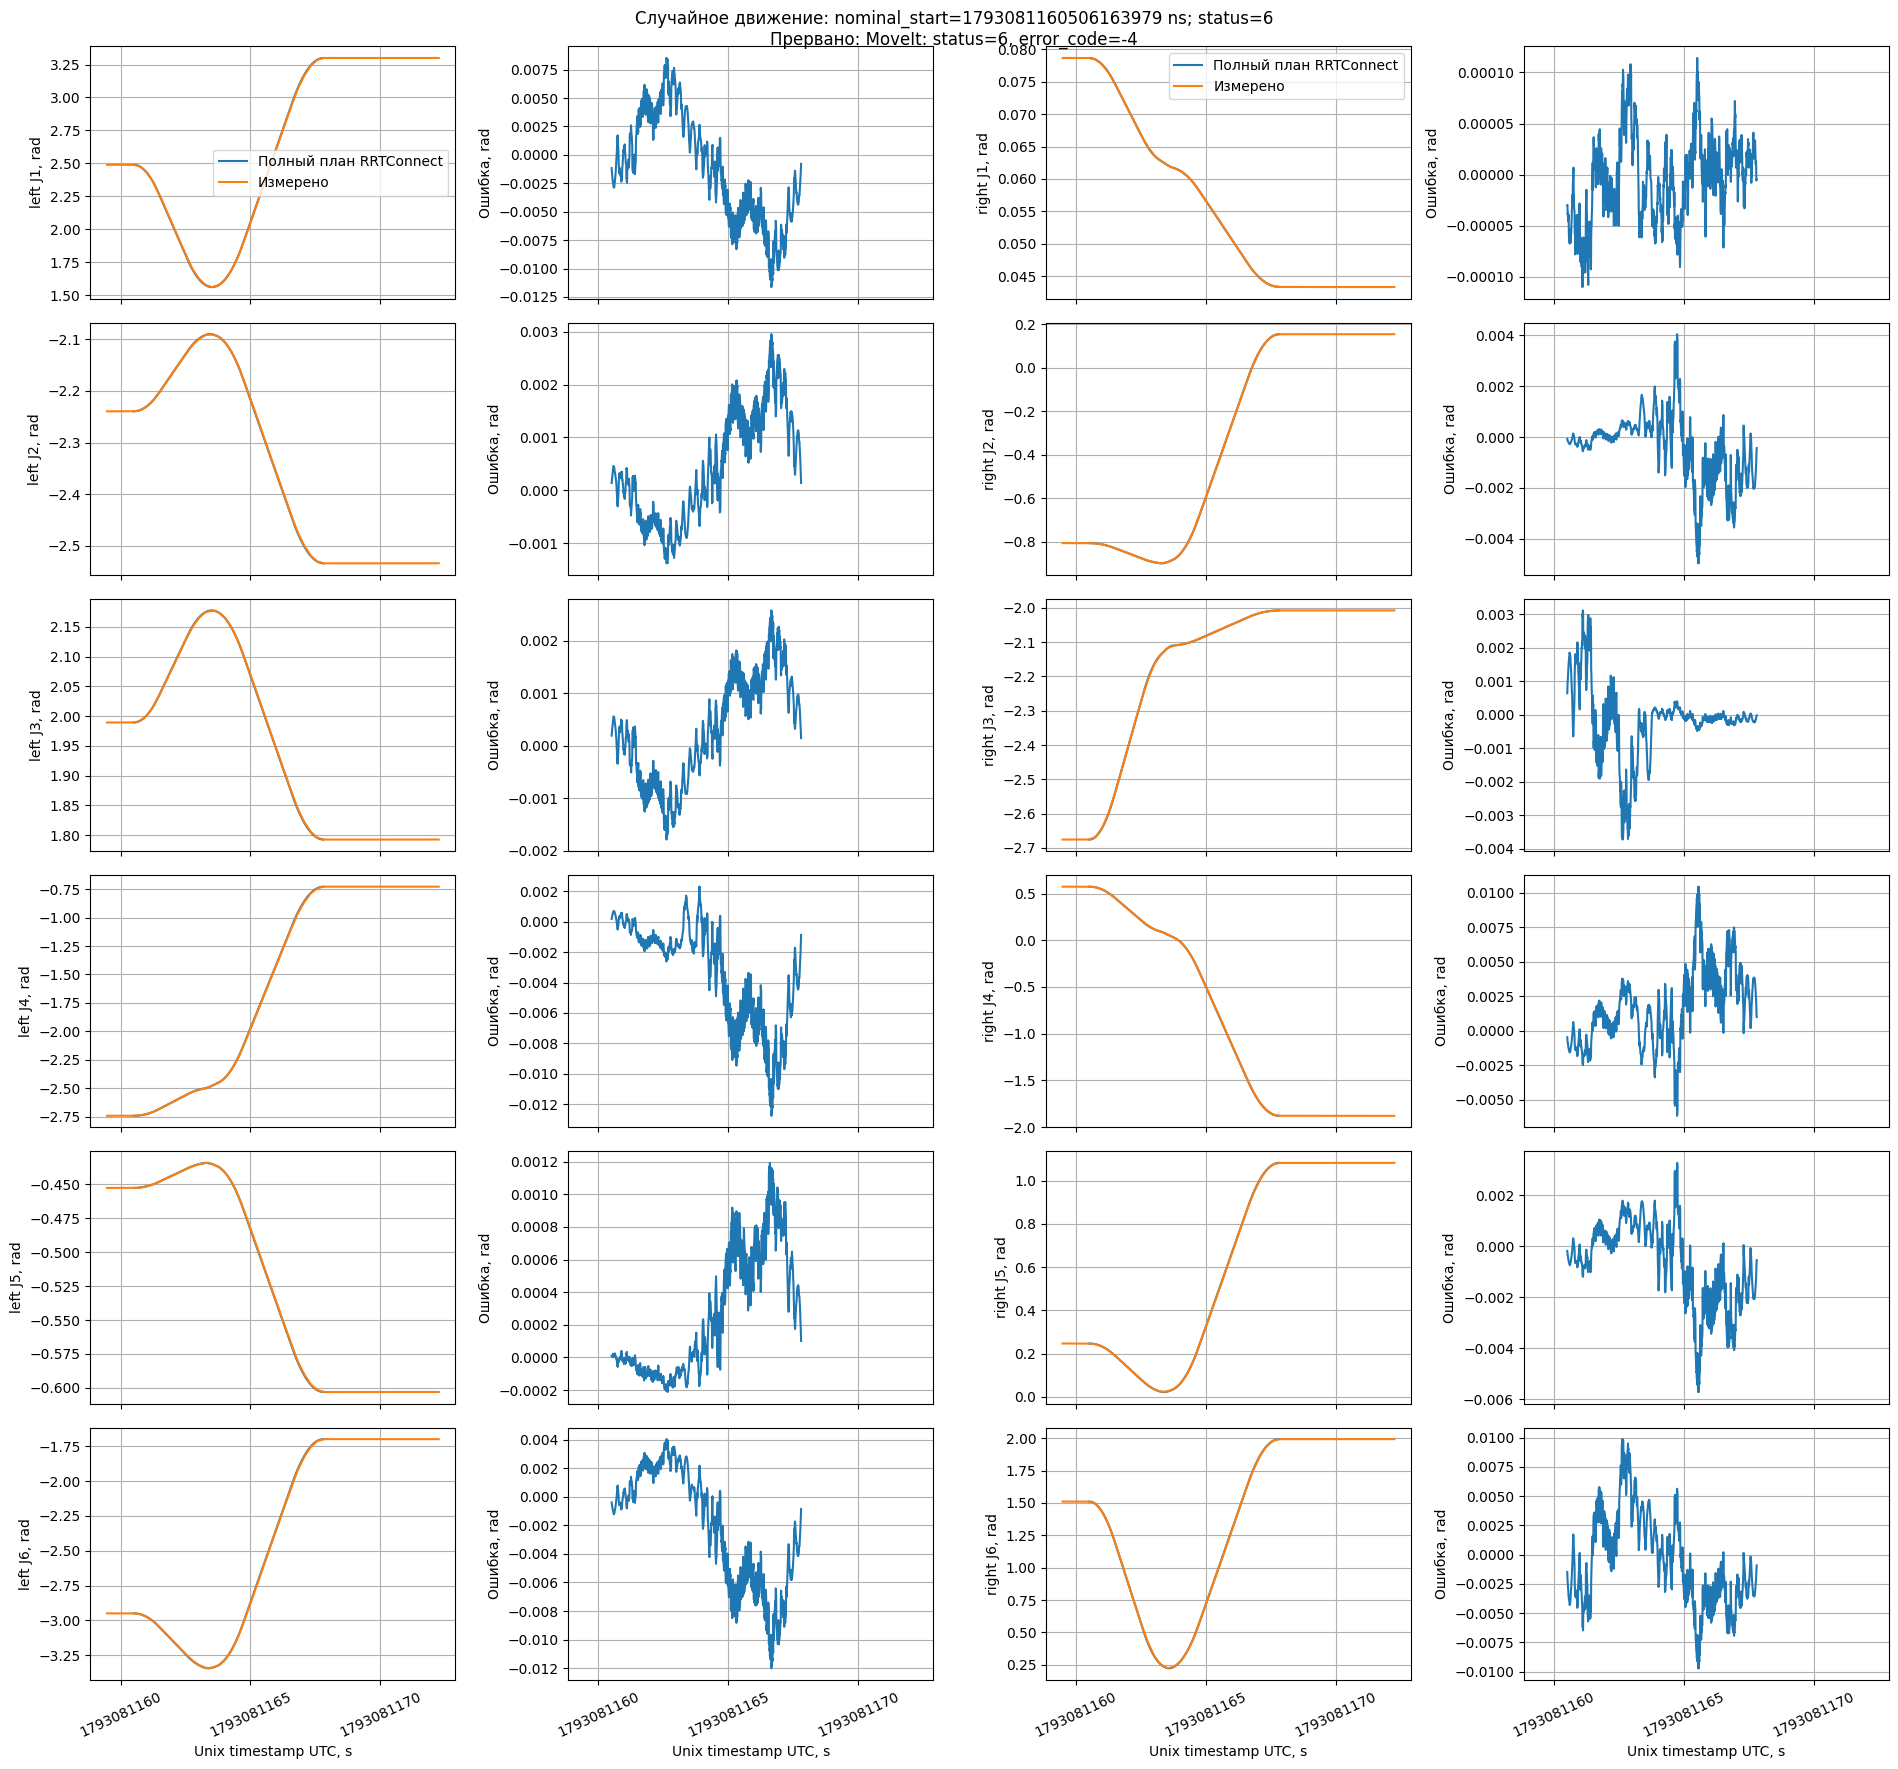

RuntimeError: MoveIt: status=6, error_code=-4

In [11]:
RUN_RANDOM = True  # True: одна случайная цель → RRTConnect → выполнение обеими руками.
RANDOM_MAX_DELTA_RAD = 3.1415  # Максимальное отклонение каждого сустава от текущей позы.
RANDOM_SEED = None          # Целое число для воспроизводимой цели; None — новая случайность.
RANDOM_ATTEMPTS = 100

if not RUN_RANDOM:
    print("RUN_RANDOM=False: случайное движение не запускается")
else:
    RUN_RANDOM = False
    for _ in range(10):
        if outstanding():
            raise RuntimeError("Предыдущая цель ещё активна/неизвестна: сначала cancel()")
        if not np.isfinite(RANDOM_MAX_DELTA_RAD) or RANDOM_MAX_DELTA_RAD <= 0:
            raise ValueError("RANDOM_MAX_DELTA_RAD должен быть конечным и положительным")
        if not isinstance(RANDOM_ATTEMPTS, int) or not 1 <= RANDOM_ATTEMPTS <= 1000:
            raise ValueError("RANDOM_ATTEMPTS должен быть целым числом от 1 до 1000")
        random_settings = approach_settings()  # Те же медленные масштабы и бюджет планирования.
        if (not all(np.isfinite(random_settings)) or not 0 < random_settings[0] <= 1
                or not 0 < random_settings[1] <= 1 or random_settings[2] <= 0):
            raise ValueError("Проверьте APPROACH_VELOCITY_SCALE / ACCELERATION_SCALE / PLANNING_S")
        driver = driver_parameters()
        if not all(d["enable_motion"] for d in driver.values()):
            raise RuntimeError("Выполнение выключено: enable_motion=false")
        if not driver["left"]["use_mock_hardware"] and not CONFIRM_DUAL_PATH_SAFE:
            raise RuntimeError("Сначала подтвердите корректность модели/сцены стенда: CONFIRM_DUAL_PATH_SAFE=True")
        random_driver = deepcopy(driver)
        random_start = stationary_pose()
        random_scene = workspace_scene()
        valid_state(random_start, "Старт случайного движения")
        random_lower = np.concatenate([driver[arm]["limits.min_position"] for arm in ARMS])
        random_upper = np.concatenate([driver[arm]["limits.max_position"] for arm in ARMS])
        if (random_lower.shape != (12,) or random_upper.shape != (12,)
                or not np.isfinite(np.r_[random_lower, random_upper]).all()
                or np.any(random_lower >= random_upper)):
            raise ValueError("Некорректные суставные ограничения драйверов")
        random_lower = np.maximum(random_lower, random_start - RANDOM_MAX_DELTA_RAD)
        random_upper = np.minimum(random_upper, random_start + RANDOM_MAX_DELTA_RAD)
        if np.any(random_lower >= random_upper):
            raise RuntimeError("Нет допустимой окрестности текущей позы")
        random_rng = np.random.default_rng(RANDOM_SEED)
        random_target = None
        for random_attempt in range(RANDOM_ATTEMPTS):
            candidate_q = random_rng.uniform(random_lower, random_upper)
            # Обе руки должны получить отличающуюся от старта цель.
            if any(np.max(abs(candidate_q[i:i+6] - random_start[i:i+6])) <= .005 for i in (0, 6)):
                continue
            validity = call(GetStateValidity, "/check_state_validity",
                GetStateValidity.Request(robot_state=measured_state(candidate_q), group_name="both_arms"))
            if validity.valid:
                random_target = candidate_q
                break
        if random_target is None:
            raise RuntimeError("Допустимая случайная цель не найдена; движение НЕ отправлено")
        display(pd.DataFrame({"joint": JOINTS, "start_rad": random_start,
                            "target_rad": random_target, "delta_rad": random_target-random_start}))
        random_goal = MoveGroup.Goal()
        random_goal.request.group_name = "both_arms"
        random_goal.request.pipeline_id = "move_group"
        random_goal.request.planner_id = "RRTConnect"
        random_goal.request.start_state = measured_state(random_start)
        random_goal.request.allowed_planning_time = random_settings[2]
        random_goal.request.num_planning_attempts = 1
        random_goal.request.max_velocity_scaling_factor = random_settings[0]
        random_goal.request.max_acceleration_scaling_factor = random_settings[1]
        random_goal.request.goal_constraints = [Constraints(joint_constraints=[
            JointConstraint(joint_name=name, position=float(value), tolerance_above=.001,
                            tolerance_below=.001, weight=1.) for name, value in zip(JOINTS, random_target)])]
        random_goal.planning_options.plan_only = True
        random_goal.planning_options.replan = False
        random_plan_record = {}
        try:
            random_plan = moveit_action(planning_client, random_goal, random_settings[2]+10,
                                        random_plan_record).planned_trajectory
        except Exception as e:
            print(f"Ошибка при планировании: {e}")
            continue
        random_jt = random_plan.joint_trajectory
        if len(random_jt.joint_names) != 12 or set(random_jt.joint_names) != set(JOINTS) or len(random_jt.points) < 2:
            raise RuntimeError("MoveIt не вернул полный план; движение НЕ отправлено")
        random_order = [random_jt.joint_names.index(name) for name in JOINTS]
        random_positions = np.array([[p.positions[i] for i in random_order] for p in random_jt.points])
        random_times = np.array([ns(p.time_from_start)*1e-9 for p in random_jt.points])
        if (not np.isfinite(random_positions).all() or random_times[0] < 0
                or np.any(np.diff(random_times) <= 0)
                or np.max(abs(random_positions[0]-random_start)) > .005
                or np.max(abs(random_positions[-1]-random_target)) > .005):
            raise RuntimeError("План не соответствует старту/цели; движение НЕ отправлено")
        if driver_parameters() != random_driver or approach_settings() != random_settings:
            raise RuntimeError("Параметры изменились во время планирования; повторите ячейку")
        if np.max(abs(stationary_pose()-random_start)) > .005:
            raise RuntimeError("Стартовая поза изменилась; повторите ячейку")
        valid_state(random_start, "Старт перед исполнением")
        valid_state(random_target, "Цель перед исполнением")
        if workspace_scene() != random_scene:
            raise RuntimeError("Сцена изменилась; повторите ячейку")
        approach_prepared = prepared = None  # Старые планы CSV/подвода больше не подходят.
        random_run = {"target": random_target.copy(), "start": random_start.copy(), "seed": RANDOM_SEED,
                      "trajectory": deepcopy(random_plan), "driver": deepcopy(random_driver),
                      "request_stamp_ns": node.get_clock().now().nanoseconds}
        try:
            moveit_action(execution_client, ExecuteTrajectory.Goal(trajectory=random_plan),
                        float(random_times[-1])+30, random_run)
        finally:
            finish_execution_plot(random_run)
        random_reached = stationary_pose()
        if np.max(abs(random_reached-random_target)) > .005:
            raise RuntimeError("Случайная цель не достигнута/не удерживается")
        print(f"Обе руки достигли случайной цели; длительность плана {random_times[-1]:.3f} s.")
        print("CSV не запускался. Для возврата к его началу заново выполните ячейки подвода.")


In [ ]:
if outstanding():
    raise RuntimeError("Цель ещё активна/неизвестна: выполните cancel() и дождитесь terminal status")
executor.shutdown(timeout_sec=2)
client.destroy()
planning_client.destroy()
execution_client.destroy()
node.destroy_node()
ctx.shutdown()
node = None
print("ROS-клиент закрыт; питание робота не изменялось")

ROS-клиент закрыт; питание робота не изменялось
